# Analysis

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Datasets

In [2]:
# load in turbine and met masts datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
scada_noloss = pd.read_parquet('../../data/cleaned/scada_noloss.parquet')
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')
reference = pd.read_parquet('../../data/cleaned/reference_power_curve.parquet')
wake = pd.read_parquet('../../data/cleaned/ALTA10_SCADA_with_wake_categories.parquet')

In [3]:
cutoff = pd.Timestamp('2026-01-14 05:40:00+00:00') 

metmasts_clean = metmasts[pd.to_datetime(metmasts['utc'], utc = True) >= cutoff]

In [4]:
scada_lowgaus = wake[wake['gaussian_style_wake_category'] == 'LOW']
scada_lowgaus['utc'] = scada_lowgaus['timestamp'] + pd.Timedelta(hours = 8)

In [23]:
one = ['WTG150', 'WTG151', 'WTG152', 'WTG153', 'WTG154', 'WTG155', 'WTG156', 'WTG157', 'WTG158', 'WTG159']

## Functions

In [5]:
def add_mm_wind_speed(data, metmast, wp_column = 'mm_wind_speed_hh', new_col = 'mm_wind_speed'):
    mm = (metmast[['utc', wp_column]]
          .assign(utc = lambda d: pd.to_datetime(d['utc'], utc = True))
          .rename(columns = {wp_column: new_col}))

    out = (data.assign(utc = lambda d: pd.to_datetime(d['utc'], utc = True))
               .merge(mm, on = 'utc', how = 'left', validate = 'many_to_one'))
    return out

In [6]:
def power_ratios(scada, ref, power_col = 'KPI_real_power_ac', mm_col = 'mm_wind_speed'):
    def snap(values, levels):
        arr = np.asarray(values, dtype = float)
        idx = np.clip(np.searchsorted(levels, arr), 1, len(levels) - 1)
        left, right = levels[idx - 1], levels[idx]
        nearest = np.where(arr - left <= right - arr, left, right)
        return np.where(np.isnan(arr), np.nan, nearest)

    # drops any existing power_ref so the lookup doesn't clash with it
    df = scada.drop(columns = 'power_ref', errors = 'ignore').copy()

    ad_levels = np.sort(ref['air_density_ref'].dropna().unique())
    ws_levels = np.sort(ref['wind_speed_ref'].dropna().unique())
    df['air_density_ref'] = snap(df['air_density'], ad_levels)

    lookup = ref[['wind_speed_ref', 'air_density_ref', 'power_ref']]

    # reference power at the turbine's wind speed and at the met mast's wind speed
    for ws_col, out_col in [('wind_speed', 'power_ref'), (mm_col, 'power_ref_mm')]:
        if ws_col not in df.columns:
            continue
        key = f'{ws_col}_ref'
        df[key] = snap(df[ws_col], ws_levels)
        df = df.merge(lookup.rename(columns = {'wind_speed_ref': key, 'power_ref': out_col}),
                      on = [key, 'air_density_ref'], how = 'left', validate = 'many_to_one')

    out = df.sort_values('utc', ignore_index = True)

    return out

In [7]:
def add_implied_ws(data, ref, power_col = 'KPI_real_power_ac', max_frac = 0.95):
    out = data.copy()
    out['ws_implied'] = np.nan
    for ad, curve in ref.groupby('air_density_ref'):
        c = (curve.sort_values('wind_speed_ref')
                  .loc[lambda x: (x['power_ref'] > 0) & (x['power_ref'] <= max_frac * x['power_ref'].max())]
                  .drop_duplicates('power_ref'))
        c = c[c['power_ref'] == c['power_ref'].cummax()]         
        if len(c) < 2:
            continue
        mask = (out['air_density_ref'] == ad) & out[power_col].between(c['power_ref'].min(), c['power_ref'].max())
        out.loc[mask, 'ws_implied'] = np.interp(out.loc[mask, power_col], c['power_ref'], c['wind_speed_ref'])
    return out

In [8]:
def add_metmast(data, metmast, wp_column = 'mm_wind_speed_hh', low = False, ws_low = 3, ws_up = 26):
    if low:
        cols1 = ['turbine', 'utc', 'wind_speed', 'KPI_real_power_ac', 'power_ref_mm']
    else:
        cols1 = ['turbine', 'utc', 'wind_speed', 'KPI_theoretical_power', 'KPI_real_power_ac', 'power_ref', 'power_ref_mm']

    cols2 = ['turbine', 'utc', 'wind_speed']
    
    a = data[cols1].assign(utc = lambda d: pd.to_datetime(d['utc'], utc = True))
    a = a[a['wind_speed'].between(ws_low, ws_up)]
    b = (metmast.assign(wind_speed = metmast[wp_column], turbine = 'Tower',
                        utc = lambda d: pd.to_datetime(d['utc'], utc = True))
                [cols2])

    combined = pd.concat([a, b], ignore_index = True)

    group_ranges = {1: (150, 159), 2: (161, 169), 3: (170, 177),
                    4: (178, 181), 5: (182, 192), 6: (193, 197)}
    rows = [(f"WTG{n}", g) for g, (lo, hi) in group_ranges.items() for n in range(lo, hi + 1)]
    rows.append(('Tower', 1))
    grouping = pd.DataFrame(rows, columns = ['turbine', 'group'])

    combined_all = combined.merge(grouping, on = 'turbine', how = 'left').sort_values('utc', ignore_index = True)

    return combined_all

In [9]:
def group_metrics(data, group, reference, low = None, up = None):
    turbines = data.loc[(data['group'] == group) & (data['turbine'] != reference)
                        & (data['turbine'] != 'Tower'), 'turbine'].unique()

    results = []
    for turbine in sorted(turbines):
        p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(
            subset = ['wind_speed_turbine', 'wind_speed_reference'])
        x, y = p['wind_speed_reference'], p['wind_speed_turbine']

        try:
            slope, intercept = np.polyfit(x, y, 1) if len(p) > 1 else (np.nan, np.nan)
        except (np.linalg.LinAlgError, ValueError):
            slope, intercept = np.nan, np.nan

        results.append({'turbine': turbine, 'reference': reference, 'n': len(p),
                        'bias': p['difference'].mean(), 'sd_diff': p['difference'].std(),
                        'corr': x.corr(y), 'slope': slope, 'intercept': intercept})

    out = pd.DataFrame(results, columns = ['turbine', 'reference', 'n', 'bias', 'sd_diff',
                                           'corr', 'slope', 'intercept'])
    return out.sort_values('corr', ascending = False, ignore_index = True)

In [10]:
def pair_turbines(data, turbine, reference, low = None, up = None):
    cols_t = ['turbine', 'utc', 'wind_speed', 'KPI_theoretical_power', 'KPI_real_power_ac', 'power_ref', 'power_ref_mm']
    cols_r = ['turbine', 'utc', 'wind_speed']

    a = data.loc[data['turbine'] == turbine, cols_t]
    b = data.loc[data['turbine'] == reference, cols_r]

    out = a.merge(b, on = 'utc', how = 'inner', suffixes = ('_1', '_2'))
    out = out.rename(columns = {'turbine_1': 'turbine', 'turbine_2': 'reference',
                                'wind_speed_1': 'wind_speed_turbine', 'wind_speed_2': 'wind_speed_reference',
                                'KPI_theoretical_power': 'theoretical_power_turbine',
                                'KPI_real_power_ac': 'real_power_turbine'})

    if low is not None:
        out = out[out['wind_speed_reference'] >= low]
    if up is not None:
        out = out[out['wind_speed_reference'] <= up]

    out['difference'] = out['wind_speed_turbine'] - out['wind_speed_reference']

    return out[['utc', 'turbine', 'reference', 'wind_speed_turbine', 'wind_speed_reference', 'difference',
                'theoretical_power_turbine', 'real_power_turbine', 'power_ref', 'power_ref_mm']]

In [11]:
def pair_turbines_month(data, turbine, reference, low = None, up = None):
    p = pair_turbines(data, turbine, reference, low = low, up = up)
    p['month'] = p['utc'].dt.tz_localize(None).dt.to_period('M')

    keys = ['month', 'turbine', 'reference']

    # wind speed difference averaged over every paired row
    ws = p.groupby(keys).agg(
        difference = ('difference', 'mean'),
        n_pairs = ('difference', 'count'),
    )

    # power sums only over rows where all three power values exist, so the sums are comparable
    pw = (p.dropna(subset = ['real_power_turbine', 'theoretical_power_turbine', 'power_ref'])
           .groupby(keys).agg(
               actual = ('real_power_turbine', 'sum'),
               theoretical = ('theoretical_power_turbine', 'sum'),
               reference_power = ('power_ref', 'sum'),
               reference_power_mm = ('power_ref_mm', 'sum'),
               n_obs = ('real_power_turbine', 'count'),
           ))

    monthly = ws.join(pw, how = 'left').reset_index()

    monthly['power_ratio_theoretical'] = np.where(
        (monthly['theoretical'] > 0) & (monthly['actual'] > 0),
        monthly['actual'] / monthly['theoretical'],
        np.nan,
    )

    monthly['power_ratio_reference'] = np.where(
        (monthly['reference_power'] > 0) & (monthly['actual'] > 0),
        monthly['actual'] / monthly['reference_power'],
        np.nan,
    )

    monthly['power_ratio_reference_mm'] = np.where(
        (monthly['reference_power_mm'] > 0) & (monthly['actual'] > 0),
        monthly['actual'] / monthly['reference_power_mm'],
        np.nan,
    )

    return monthly

In [12]:
def plot_pair_turbines_month(data, turbine, reference, ratio_col = 'power_ratio_reference', 
                             low = None, up = None, min_obs = 0, ma = '7D', ma_min_periods = 144):
    # monthly summary
    df = pair_turbines_month(data, turbine, reference, low = low, up = up).sort_values('month')
    df['start'] = df['month'].dt.start_time.dt.tz_localize('UTC')
    df['end'] = df['month'].dt.end_time.dt.tz_localize('UTC')
    df['mid'] = df['start'] + (df['end'] - df['start']) / 2
    df.loc[df['n_obs'].fillna(0) < min_obs, ratio_col] = np.nan

    # 10-min difference on a regular grid so gaps show as breaks
    p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(
        subset = ['wind_speed_turbine', 'wind_speed_reference'])
    s = p.set_index('utc')['difference'].sort_index().asfreq('10min')
    rolling = s.rolling(ma, center = True, min_periods = ma_min_periods).mean() if ma is not None else None

    ratio_labels = {'power_ratio_theoretical': 'Real / Theoretical',
                    'power_ratio_reference': 'Real / Reference'}

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize = (12, 8), sharex = True)

    # Top: monthly power ratio
    ax1.plot(df['mid'], df[ratio_col], lw = 1, alpha = 0.7, marker = 'o')
    ax1.axhline(1, color = 'black', lw = 0.8)
    ax1.set_ylabel(f"Power Ratio\n({ratio_labels.get(ratio_col, ratio_col)})")
    lo, hi = df[ratio_col].min(), df[ratio_col].max()
    ax1.set_ylim(min(0.75, lo if pd.notna(lo) else 0.75) - 0.02, max(1.25, hi if pd.notna(hi) else 1.25) + 0.02)
    ax1.set_title(f'Monthly Power Ratio: {turbine}')
    ax1.grid(alpha = 0.3)

    # Top: monthly power ratio
    ax2.plot(df['mid'], df['power_ratio_reference_mm'], lw = 1, alpha = 0.7, marker = 'o')
    ax2.axhline(1, color = 'black', lw = 0.8)
    ax2.set_ylabel(f"Power Ratio\n(power_ratio_reference_mm)")
    lo, hi = df['power_ratio_reference_mm'].min(), df['power_ratio_reference_mm'].max()
    ax2.set_ylim(min(0.75, lo if pd.notna(lo) else 0.75) - 0.02, max(1.25, hi if pd.notna(hi) else 1.25) + 0.02)
    ax2.set_title(f'Monthly Power Ratio (Metmast Wind Measurment): {turbine}')
    ax2.grid(alpha = 0.3)

    # Bottom: 10-min difference, moving average, and monthly mean
    ax3.plot(s.index, s.values, lw = 0.5, alpha = 0.5, label = '10-min')
    if rolling is not None:
        ax3.plot(rolling.index, rolling.values, color = 'red', lw = 1.5, label = f'{ma} moving average')
    ax3.axhline(0, color = 'black', lw = 0.8, ls = ':')
    ax3.set_ylabel(f'Wind Speed Difference (m/s)\n{turbine} − {reference}')
    ax3.set_xlabel('Date (UTC)')
    ax3.set_title(f'Wind Speed Difference: {turbine} vs {reference}, n = {s.notna().sum()}')
    ax3.legend(loc = 'upper right')
    ax3.grid(alpha = 0.3)

    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

In [13]:
def plot_pair_diff_ts(data, turbine, reference, month = None, low = None, up = None,
                      ma = '7D', min_periods = 144):
    p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(
        subset = ['wind_speed_turbine', 'wind_speed_reference'])

    # regular 10-min grid so gaps show as breaks instead of straight lines
    s = p.set_index('utc')['difference'].sort_index().asfreq('10min')

    # moving average on the full series, centered, so month edges aren't truncated
    rolling = s.rolling(ma, center = True, min_periods = min_periods).mean() if ma is not None else None

    if month is not None:
        m = pd.Period(month, freq = 'M')
        start = m.start_time.tz_localize('UTC')
        end = m.end_time.tz_localize('UTC')
        s = s.loc[start:end]
        if rolling is not None:
            rolling = rolling.loc[start:end]

    n = s.notna().sum()
    period = f', {month}' if month is not None else ''

    fig, ax = plt.subplots(figsize = (12, 5))
    ax.plot(s.index, s.values, lw = 0.5, alpha = 0.6, label = f'Difference {turbine} − {reference}')
    if rolling is not None:
        ax.plot(rolling.index, rolling.values, color = 'red', lw = 1.5, label = f'{ma} moving average (centered)')
    ax.axhline(0, color = 'k', lw = 0.8)
    ax.set(xlabel = 'Date/time (UTC)', ylabel = 'Wind speed difference (m/s)',
           title = f'{turbine} − {reference} Wind Speed Difference{period}, n = {n}')
    ax.legend()
    ax.grid(alpha = 0.3)
    fig.autofmt_xdate()
    plt.show()

In [14]:
def wind_speed_analysis(data, ref, metmast, low = 4, up = 15, group = 1):
    group_ranges = {1: (150, 159), 2: (161, 169), 3: (170, 177),
                    4: (178, 181), 5: (182, 192), 6: (193, 197)}
    rows = [(f"WTG{n}", g) for g, (lo, hi) in group_ranges.items() for n in range(lo, hi + 1)]
    grouping = pd.DataFrame(rows, columns = ['turbine', 'group'])

    df = data[data['turbine'] != 'Tower'].merge(grouping, on = 'turbine', how = 'left')
    if group is not None:
        df = df[df['group'] == group]

    a = power_ratios(add_mm_wind_speed(df, metmast), ref)

    d = a[(a['mm_wind_speed'] >= low) & (a['mm_wind_speed'] < up)
          & (a['KPI_real_power_ac'] > 0)
          & a['wind_speed'].notna()].copy()

    d['diff_mm'] = d['wind_speed'] - d['mm_wind_speed']
    d['bin'] = pd.cut(d['mm_wind_speed'], np.arange(low, up + 1, 1), right = False)

    d = add_implied_ws(d, ref)
    d['diff_power'] = d['wind_speed'] - d['ws_implied']

    d['month'] = d['utc'].dt.tz_localize(None).dt.to_period('M')
    
    return d[['utc', 'month', 'turbine', 'group', 'bin', 'KPI_real_power_ac', 'power_ref', 'wind_speed',
              'mm_wind_speed', 'ws_implied', 'diff_mm', 'diff_power']].reset_index(drop = True)

In [46]:
def wind_speed_analysis_within_group(data, ref, low = 4, up = 15, group = 1):
    group_ranges = {1: (150, 159), 2: (161, 169), 3: (170, 177),
                    4: (178, 181), 5: (182, 192), 6: (193, 197)}
    rows = [(f"WTG{n}", g) for g, (lo, hi) in group_ranges.items() for n in range(lo, hi + 1)]
    grouping = pd.DataFrame(rows, columns = ['turbine', 'group'])

    df = data.merge(grouping, on = 'turbine', how = 'left')
    if group is not None:
        df = df[df['group'] == group]

    a = power_ratios(df, ref)

    d = a[(a['wind_speed'] >= low) & (a['wind_speed'] < up)
          & (a['KPI_real_power_ac'] > 0)
          & a['wind_speed'].notna()].copy()

    d['bin'] = pd.cut(d['wind_speed'], np.arange(low, up + 1, 1), right = False)

    d = add_implied_ws(d, ref)
    d['diff_power'] = d['wind_speed'] - d['ws_implied']

    d['month'] = d['utc'].dt.tz_localize(None).dt.to_period('M')
    
    return d[['utc', 'month', 'turbine', 'group', 'bin', 'KPI_real_power_ac', 'power_ref', 'wind_speed',
              'ws_implied', 'air_density', 'diff_power']].reset_index(drop = True)

In [15]:
def bin_summary(d, min_n = 30, wide = False):
    df = d.assign(power_ratio = d['KPI_real_power_ac'] / d['power_ref'].replace(0, np.nan))

    out = (df.groupby(['turbine', 'bin'], observed = True)
             .agg(n = ('diff_mm', 'size'),
                  median_diff_mm = ('diff_mm', 'median'),
                  median_diff_power = ('diff_power', 'median'),
                  n_power = ('diff_power', 'count'),
                  median_power_ratio = ('power_ratio', 'median'))
             .reset_index())

    # blanks out bins with too few readings
    out.loc[out['n'] < min_n, ['median_diff_mm', 'median_power_ratio']] = np.nan
    out.loc[out['n_power'] < min_n, 'median_diff_power'] = np.nan

    if wide:
        return out.pivot(index = 'turbine', columns = 'bin',
                         values = ['median_diff_mm', 'median_diff_power', 'median_power_ratio'])
    return out

In [16]:
def plot_bin_summary(summary, turbine, ylim_diff = None, ylim_ratio = None):
    s = summary[summary['turbine'] == turbine].copy()
    s['ws'] = [iv.mid for iv in s['bin']]
    s = s.sort_values('ws')

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (10, 7), sharex = True,
                                   gridspec_kw = {'height_ratios': [1.4, 1]})

    # Top: wind speed differences
    ax1.plot(s['ws'], s['median_diff_mm'], marker = 'o', lw = 1.5, label = 'Nacelle − met mast')
    ax1.plot(s['ws'], s['median_diff_power'], marker = 's', lw = 1.5, label = 'Nacelle − power-implied')
    ax1.axhline(0, color = 'k', lw = 0.8)
    ax1.set_ylabel('Median wind speed difference (m/s)')
    ax1.set_title(f'{turbine}: median by met mast wind speed bin')
    ax1.legend()
    ax1.grid(alpha = 0.3)
    if ylim_diff is not None:
        ax1.set_ylim(*ylim_diff)

    # Bottom: power ratio
    ax2.plot(s['ws'], s['median_power_ratio'], marker = 'o', lw = 1.5, color = 'tab:green')
    ax2.axhline(1, color = 'k', lw = 0.8)
    ax2.set_ylabel('Median power ratio\n(Real / Reference)')
    ax2.set_xlabel('Met mast wind speed (m/s, bin centre)')
    ax2.grid(alpha = 0.3)
    if ylim_ratio is not None:
        ax2.set_ylim(*ylim_ratio)

    # bin widths as x tick labels
    ax2.set_xticks(s['ws'])
    ax2.set_xticklabels([f'{iv.left:g}–{iv.right:g}' for iv in s['bin']], rotation = 30, ha = 'right')

    fig.tight_layout()
    plt.show()

In [17]:
def flag_anemometer_bias(summary, ws_range = (5, 10), min_n = 30,
                         off_tol = 0.3, slope_tol = 0.05, mm_tol = 0.5):
    s = summary.copy()
    s['ws'] = s['bin'].apply(lambda iv: iv.mid).astype(float)
    s = s[s['ws'].between(*ws_range) & (s['n_power'] >= min_n)]
    ratio_col = 'power_ratio_sum' if 'power_ratio_sum' in s.columns else 'median_power_ratio'

    # per-turbine metrics over the middle bins
    rows = []
    for turbine, g in s.groupby('turbine'):
        gp = g.dropna(subset = ['median_diff_power'])
        slope = np.polyfit(gp['ws'], gp['median_diff_power'], 1)[0] if len(gp) >= 3 else np.nan
        rows.append({'turbine': turbine, 'n_bins': len(gp),
                     'off_power': g['median_diff_power'].median(),
                     'slope_power': slope,
                     'off_mm': g['median_diff_mm'].median(),
                     'ratio': g[ratio_col].median()})
    m = pd.DataFrame(rows)

    # relative to the median of all turbines in the summary
    for col in ['off_power', 'slope_power', 'off_mm', 'ratio']:
        m[f'rel_{col}'] = m[col] - m[col].median()

    big_off = m['rel_off_power'].abs() > off_tol
    big_slope = m['rel_slope_power'].abs() > slope_tol
    big_mm = m['rel_off_mm'].abs() > mm_tol
    same_sign = np.sign(m['rel_off_power']) == np.sign(m['rel_off_mm'])

    m['flag'] = np.select(
        [big_off & big_mm & same_sign,
         big_slope,
         big_off & ~big_mm & (m['rel_off_power'] > 0),
         big_off & ~big_mm,
         big_mm & ~big_off],
        ['anemometer offset',
         'anemometer scaling / performance varies with wind speed',
         'possible underperformance',
         'reads low vs power (check)',
         'location (different wind, anemometer OK)'],
        default = 'ok')

    order = ['turbine', 'flag', 'n_bins', 'off_power', 'rel_off_power', 'slope_power',
             'rel_slope_power', 'off_mm', 'rel_off_mm', 'ratio', 'rel_ratio']
    return m[order].sort_values(['flag', 'rel_off_power'], key = lambda c: c if c.name != 'flag' else c == 'ok',
                                ignore_index = True)

In [18]:
def plot_turbine_diff_metmast(data, d, turbine, reference = 'Tower', month = None, low = None, up = None,
                      ma = '7D', min_periods = 144, bin_width = 0.5, min_n = 30):
    p = pair_turbines(data, turbine, reference, low = low, up = up).dropna(subset = ['wind_speed_turbine', 'wind_speed_reference'])
    s = p.set_index('utc')['difference'].sort_index().asfreq('10min')
    rolling = s.rolling(ma, center = True, min_periods = min_periods).mean() if ma is not None else None

    t = d[d['turbine'] == turbine].dropna(subset = ['mm_wind_speed', 'diff_mm'])

    if month is not None:
        m = pd.Period(month, freq = 'M')
        start = m.start_time.tz_localize('UTC')
        end = m.end_time.tz_localize('UTC')
        s = s.loc[start:end]
        if rolling is not None:
            rolling = rolling.loc[start:end]
        t = t[t['utc'].between(start, end)]

    edges = np.arange(np.floor(t['mm_wind_speed'].min()), np.ceil(t['mm_wind_speed'].max()) + bin_width, bin_width)
    t = t.assign(bin = pd.cut(t['mm_wind_speed'], edges, include_lowest = True))
    stats = (t.groupby('bin', observed = True)['diff_mm']
              .agg(median = 'median', q25 = lambda x: x.quantile(0.25), q75 = lambda x: x.quantile(0.75), n = 'size')
              .query('n >= @min_n'))
    centers = [iv.mid for iv in stats.index]

    period = f', {month}' if month is not None else ''
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (18, 6), sharey = True,
                                   gridspec_kw = {'width_ratios': [1.5, 1]})

    ax1.plot(s.index, s.values, lw = 0.5, color = '#8FA9C4', label = '10-min')
    if rolling is not None:
        ax1.plot(rolling.index, rolling.values, color = 'red', lw = 1.5, label = f'{ma} moving average (centered)')
    ax1.axhline(0, color = 'k', lw = 0.8)
    ax1.set(xlabel = 'Date/time', ylabel = f'{turbine} − {reference} (m/s)',
            title = f'Wind Speed Difference Over Time, n = {s.notna().sum()}')
    ax1.legend(loc = 'upper right')
    ax1.grid(axis = 'y', alpha = 0.3)
    for label in ax1.get_xticklabels():
        label.set_rotation(30)
        label.set_ha('right')

    # Right: difference vs met mast wind speed
    ax2.scatter(t['mm_wind_speed'], t['diff_mm'], s = 3, color = '#8FA9C4', alpha = 0.5, label = '10-min')
    ax2.fill_between(centers, stats['q25'], stats['q75'], color = 'red', alpha = 0.2, label = 'Interquartile range')
    ax2.plot(centers, stats['median'], color = 'red', lw = 2, marker = 'o', ms = 4, label = 'Bin median')
    ax2.axhline(0, color = 'k', lw = 0.8)
    ax2.set(xlabel = 'Met Mast Wind Speed (m/s)', title = f'Wind Speed Difference Over Wind Speed, n = {len(t)}')
    ax2.legend(loc = 'upper right')
    ax2.grid(axis = 'y', alpha = 0.3)

    fig.suptitle(f'{turbine} − {reference} Wind Speed Difference{period}')
    fig.tight_layout()
    plt.show()

In [19]:
def plot_turbine_diff_power(d, turbine, month = None, low = None, up = None, ma = '14D',
                       min_periods = 144, bin_width = 0.5, min_n = 30):
    t = d[d['turbine'] == turbine].dropna(subset = ['utc', 'mm_wind_speed', 'diff_power'])

    # optional met mast wind speed limits
    if low is not None:
        t = t[t['mm_wind_speed'] >= low]
    if up is not None:
        t = t[t['mm_wind_speed'] <= up]

    # time series on a regular 10-min grid, moving average on the full series
    s = t.set_index('utc')['diff_power'].sort_index().asfreq('10min')
    rolling = s.rolling(ma, center = True, min_periods = min_periods).mean() if ma is not None else None

    if month is not None:
        m = pd.Period(month, freq = 'M')
        start = m.start_time.tz_localize('UTC')
        end = m.end_time.tz_localize('UTC')
        s = s.loc[start:end]
        if rolling is not None:
            rolling = rolling.loc[start:end]
        t = t[t['utc'].between(start, end)]

    # binned median and interquartile range by met mast wind speed
    edges = np.arange(np.floor(t['mm_wind_speed'].min()), np.ceil(t['mm_wind_speed'].max()) + bin_width, bin_width)
    t = t.assign(bin = pd.cut(t['mm_wind_speed'], edges, include_lowest = True))
    stats = (t.groupby('bin', observed = True)['diff_power']
              .agg(median = 'median', q25 = lambda x: x.quantile(0.25), q75 = lambda x: x.quantile(0.75), n = 'size')
              .query('n >= @min_n'))
    centers = [iv.mid for iv in stats.index]

    period = f', {month}' if month is not None else ''
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (16, 5.5), sharey = True,
                                   gridspec_kw = {'width_ratios': [1.5, 1]})

    # Left: over time
    ax1.plot(s.index, s.values, lw = 0.5, alpha = 0.6, label = '10-min')
    if rolling is not None:
        ax1.plot(rolling.index, rolling.values, color = 'red', lw = 1.5, label = f'{ma} moving average (centered)')
    ax1.axhline(0, color = 'k', lw = 0.8)
    ax1.set_ylim(-5, 5)
    ax1.set(xlabel = 'Date/time (UTC)', ylabel = 'Nacelle − power-implied wind speed (m/s)',
            title = f'Over time, n = {s.notna().sum()}')
    ax1.legend(loc = 'upper right')
    ax1.grid(alpha = 0.3)
    for label in ax1.get_xticklabels():
        label.set_rotation(30)
        label.set_ha('right')

    # Right: vs met mast wind speed
    ax2.scatter(t['mm_wind_speed'], t['diff_power'], s = 3, alpha = 0.15, label = '10-min')
    ax2.fill_between(centers, stats['q25'], stats['q75'], color = 'red', alpha = 0.2, label = 'Interquartile range')
    ax2.plot(centers, stats['median'], color = 'red', lw = 2, marker = 'o', ms = 4, label = 'Bin median')
    ax2.axhline(0, color = 'k', lw = 0.8)
    ax2.set_ylim(-5, 5)
    ax2.set(xlabel = 'Met mast wind speed (m/s)', title = f'Vs met mast wind speed, n = {len(t)}')
    ax2.legend(loc = 'upper right')
    ax2.grid(alpha = 0.3)

    fig.suptitle(f'{turbine}: Nacelle vs Power-Implied Wind Speed{period}')
    fig.tight_layout()
    plt.show()

In [20]:
def compare_to_others(d, turbine, min_n = 0):
    names = {'wind_speed': 'ws', 'KPI_real_power_ac': 'power', 'diff_mm': 'diff_mm'}
    keys = ['month', 'bin']

    def stats(df, prefix):
        agg = {}
        for col, short in names.items():
            agg[f'{prefix}_{short}_median'] = (col, 'median')
            agg[f'{prefix}_{short}_std'] = (col, 'std')
        agg[f'{prefix}_n'] = ('wind_speed', 'size')
        return df.groupby(keys, observed = True).agg(**agg)

    t = stats(d[d['turbine'] == turbine], 'turbine')
    others_df = d[d['turbine'] != turbine]
    o = stats(others_df, 'others')
    o['others_n_turbines'] = others_df.groupby(keys, observed = True)['turbine'].nunique()

    out = t.join(o, how = 'outer')

    # difference between the turbine and the others, per variable
    for short in names.values():
        out[f'delta_{short}_median'] = out[f'turbine_{short}_median'] - out[f'others_{short}_median']

    # blanks out cells with too few readings
    if min_n > 0:
        for prefix in ['turbine', 'others']:
            cols = [c for c in out.columns if c.startswith(prefix) and c.endswith(('_median', '_std'))]
            out.loc[out[f'{prefix}_n'] < min_n, cols] = np.nan

    # groups columns by variable: turbine, others, difference, then spreads, then counts
    order = []
    for short in names.values():
        order += [f'turbine_{short}_median', f'others_{short}_median', f'delta_{short}_median',
                  f'turbine_{short}_std', f'others_{short}_std']
    order += ['turbine_n', 'others_n', 'others_n_turbines']

    return out[order].reset_index().sort_values(keys, ignore_index = True)

In [49]:
def compare_to_others_within_group(d, turbine, min_n = 0):
    names = {'wind_speed': 'ws', 'KPI_real_power_ac': 'power'}
    keys = ['month', 'bin']

    def stats(df, prefix):
        agg = {}
        for col, short in names.items():
            agg[f'{prefix}_{short}_median'] = (col, 'median')
            agg[f'{prefix}_{short}_std'] = (col, 'std')
        agg[f'{prefix}_n'] = ('wind_speed', 'size')
        return df.groupby(keys, observed = True).agg(**agg)

    t = stats(d[d['turbine'] == turbine], 'turbine')
    others_df = d[d['turbine'] != turbine]
    o = stats(others_df, 'others')
    o['others_n_turbines'] = others_df.groupby(keys, observed = True)['turbine'].nunique()

    out = t.join(o, how = 'outer')

    # difference between the turbine and the others, per variable
    for short in names.values():
        out[f'delta_{short}_median'] = out[f'turbine_{short}_median'] - out[f'others_{short}_median']

    # blanks out cells with too few readings
    if min_n > 0:
        for prefix in ['turbine', 'others']:
            cols = [c for c in out.columns if c.startswith(prefix) and c.endswith(('_median', '_std'))]
            out.loc[out[f'{prefix}_n'] < min_n, cols] = np.nan

    # groups columns by variable: turbine, others, difference, then spreads, then counts
    order = []
    for short in names.values():
        order += [f'turbine_{short}_median', f'others_{short}_median', f'delta_{short}_median',
                  f'turbine_{short}_std', f'others_{short}_std']
    order += ['turbine_n', 'others_n', 'others_n_turbines']

    return out[order].reset_index().sort_values(keys, ignore_index = True)

## Generating Dataset

In [21]:
data = add_mm_wind_speed(scada_noloss, metmasts_clean)
data = power_ratios(data, reference, power_col = 'KPI_real_power_ac')
data = add_metmast(data, metmasts_clean, wp_column = 'mm_wind_speed_hh', low = False, ws_low = 3, ws_up = 26)

In [24]:
pairs = []
for t in one:
    pairs.append(pair_turbines(data, t, 'Tower', low = 4, up = 25))

all_pairs = pd.concat(pairs, ignore_index = True)

In [25]:
all_pairs

,utc,turbine,reference,wind_speed_turbine,wind_speed_reference,difference,theoretical_power_turbine,real_power_turbine,power_ref,power_ref_mm
0,2026-01-14 11:20:00+00:00,WTG150,Tower,4.329909,4.207097,0.122812,137.47849,0.0,137.0,67.0
1,2026-01-14 12:00:00+00:00,WTG150,Tower,3.664453,4.134627,-0.470174,0.00000,0.0,9.0,67.0
2,2026-01-14 12:10:00+00:00,WTG150,Tower,3.503992,4.720625,-1.216633,0.00000,0.0,9.0,137.0
3,2026-01-14 12:40:00+00:00,WTG150,Tower,3.096051,4.073750,-0.977699,0.00000,0.0,1.0,63.0
4,2026-01-14 16:20:00+00:00,WTG150,Tower,3.670770,4.192500,-0.521730,0.00000,0.0,9.0,67.0
...,...,...,...,...,...,...,...,...,...,...
249519,2026-09-29 14:10:00+00:00,WTG159,Tower,19.487625,15.223478,4.264147,2792.74800,0.0,2850.0,2850.0
249520,2026-09-29 14:20:00+00:00,WTG159,Tower,19.790451,15.210000,4.580451,2793.89530,0.0,2850.0,2850.0
249521,2026-09-29 14:30:00+00:00,WTG159,Tower,19.450239,15.423529,4.026709,2792.85670,0.0,2850.0,2850.0
249522,2026-09-29 14:40:00+00:00,WTG159,Tower,17.618838,14.712941,2.905897,2784.24200,0.0,2850.0,2850.0


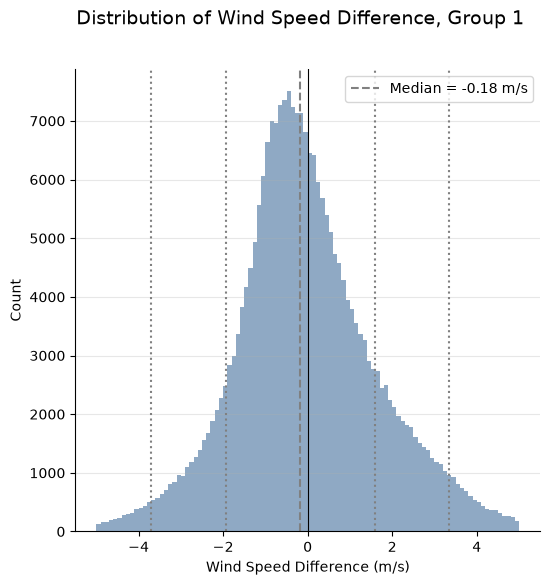

In [26]:
fig, ax = plt.subplots(figsize = (6, 6))
fig.suptitle('Distribution of Wind Speed Difference, Group 1', fontsize = 14)
ax.hist(all_pairs['difference'].dropna(), bins = 100, range = (-5, 5), color = '#8FA9C4')
ax.axvline(0, color = 'black', lw = 0.8)
ax.axvline(all_pairs['difference'].median(), color = 'grey', lw = 1.5, ls = '--',
           label = f"Median = {all_pairs['difference'].median():+.2f} m/s")
ax.axvline(all_pairs['difference'].median() + all_pairs['difference'].std(), color = 'grey', lw = 1.5, ls = ':')
ax.axvline(all_pairs['difference'].median() - all_pairs['difference'].std(), color = 'grey', lw = 1.5, ls = ':')
ax.axvline(all_pairs['difference'].median() + 2 * all_pairs['difference'].std(), color = 'grey', lw = 1.5, ls = ':')
ax.axvline(all_pairs['difference'].median() - 2 * all_pairs['difference'].std(), color = 'grey', lw = 1.5, ls = ':')
ax.set(xlabel = 'Wind Speed Difference (m/s)', ylabel = 'Count')
ax.legend()
ax.grid(axis = 'y', alpha = 0.3)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.show()

In [27]:
group1 = group_metrics(data, 1, 'Tower', low = 4, up = 25)

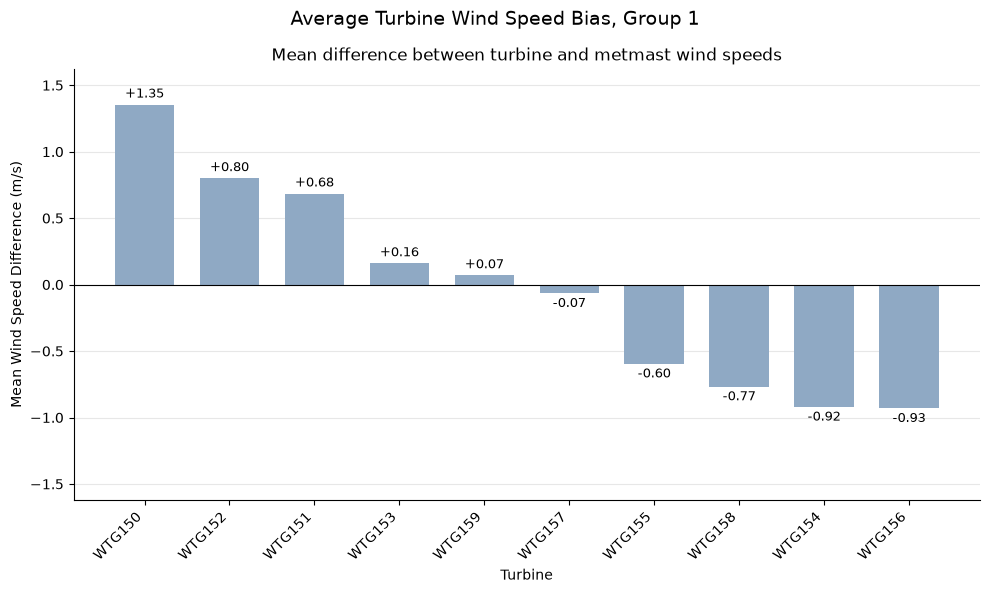

In [28]:
g = group1.sort_values('bias', ascending = False)

fig, ax = plt.subplots(figsize = (10, 6))
bars = ax.bar(g['turbine'], g['bias'], color = '#8FA9C4', width = 0.7)

ax.axhline(0, color = 'black', lw = 0.8)
ax.bar_label(bars, fmt = '%+.2f', padding = 3, fontsize = 9)

fig.suptitle('Average Turbine Wind Speed Bias, Group 1', fontsize = 14)
ax.set_ylabel('Mean Wind Speed Difference (m/s)')
ax.set_xlabel('Turbine')
ax.set_title('Mean difference between turbine and metmast wind speeds', fontsize = 12)
ax.grid(axis = 'y', alpha = 0.3)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.xticks(rotation = 45, ha = 'right')

# leaves room for the labels above and below the bars
lim = g['bias'].abs().max() * 1.2
ax.set_ylim(-lim, lim)

fig.tight_layout()
plt.show()

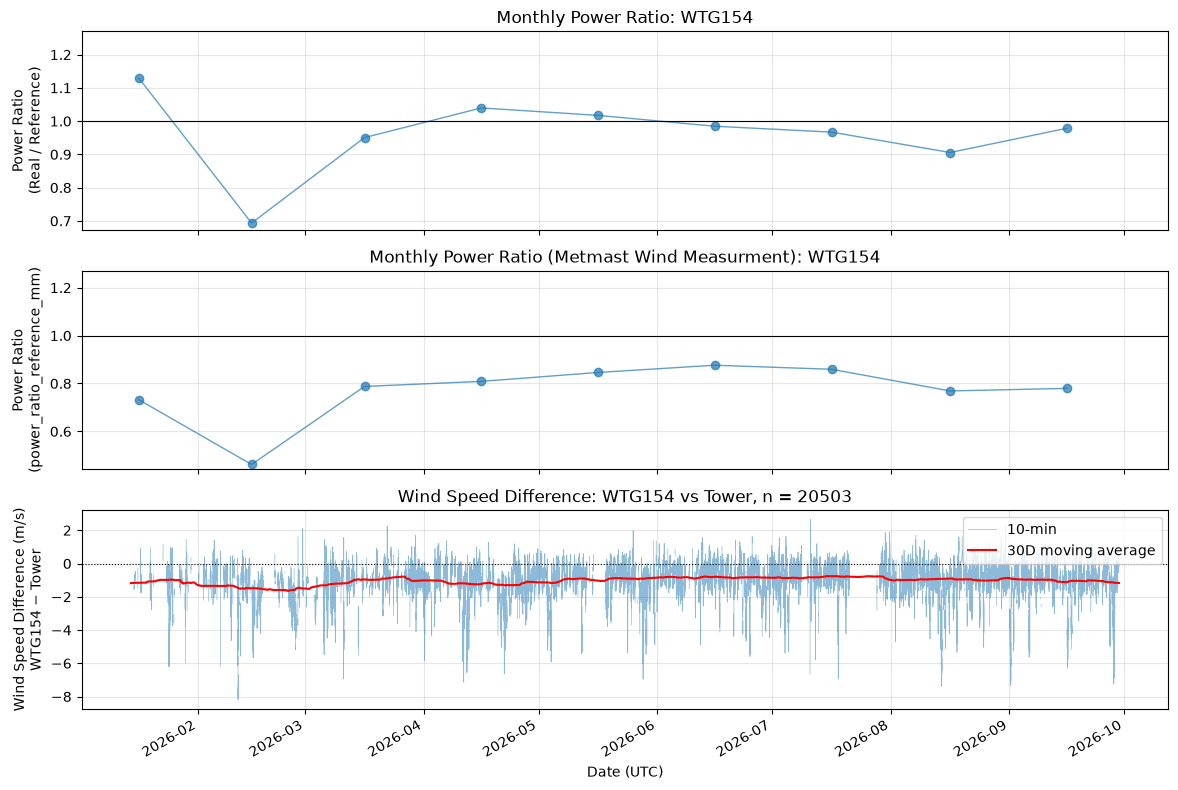

In [29]:
plot_pair_turbines_month(data, 'WTG154', 'Tower', ratio_col = 'power_ratio_reference', 
                             low = 4, up = 15, min_obs = 0, ma = '30D', ma_min_periods = 144)

In [30]:
pair_turbines_month(data, 'WTG154', 'Tower', low = 4, up = 15)

,month,turbine,reference,difference,n_pairs,actual,theoretical,reference_power,reference_power_mm,n_obs,power_ratio_theoretical,power_ratio_reference,power_ratio_reference_mm
0,2026-01,WTG154,Tower,-1.161634,421,2.215124e+05,1.667194e+05,196059.0,302402.0,408,1.328653,1.129825,0.732510
1,2026-02,WTG154,Tower,-1.482832,1551,8.110595e+05,1.075506e+06,1169433.0,1756309.0,1550,0.754119,0.693549,0.461798
2,2026-03,WTG154,Tower,-0.959195,1979,2.280355e+06,2.179788e+06,2399131.0,2895236.0,1979,1.046136,0.950492,0.787623
3,2026-04,WTG154,Tower,-1.226288,2719,3.640408e+06,3.183085e+06,3501471.0,4501076.0,2719,1.143673,1.039680,0.808786
4,2026-05,WTG154,Tower,-1.022168,2506,3.542096e+06,3.259576e+06,3481794.0,4186819.0,2506,1.086674,1.017319,0.846011
5,2026-06,WTG154,Tower,-0.797425,2638,4.616636e+06,4.374073e+06,4688512.0,5268433.0,2638,1.055455,0.984670,0.876283
6,2026-07,WTG154,Tower,-0.754736,2422,3.968614e+06,3.782538e+06,4104179.0,4618621.0,2421,1.049194,0.966969,0.859264
7,2026-08,WTG154,Tower,-0.904031,3424,4.197996e+06,4.318015e+06,4635400.0,5460230.0,3271,0.972205,0.905638,0.768831
8,2026-09,WTG154,Tower,-1.128262,2843,3.511390e+06,3.370419e+06,3588269.0,4504267.0,2831,1.041826,0.978575,0.779570


## Second Attempt

In [76]:
def compare_to_group(d, turbine, low = 4, up = 12, min_others = 3):
    # median of the other turbines at each timestamp
    others = (d[d['turbine'] != turbine]
              .groupby('utc')
              .agg(ref_ws = ('wind_speed', 'median'),
                   ref_power = ('KPI_real_power_ac', 'median'),
                   ref_implied = ('ws_implied', 'median'),
                   ref_diff_power = ('diff_power', 'median'),
                   n_others = ('turbine', 'nunique')))

    t = d[d['turbine'] == turbine].set_index('utc')
    m = t.join(others, how = 'inner')

    # filters and bins on the group's wind speed, not the turbine's own
    m = m[(m['n_others'] >= min_others) & (m['ref_ws'] >= low) & (m['ref_ws'] < up)].copy()
    m['ref_bin'] = pd.cut(m['ref_ws'], np.arange(low, up + 1, 1), right = False)

    m['ws_rel'] = m['wind_speed'] - m['ref_ws']
    m['power_rel'] = m['KPI_real_power_ac'] - m['ref_power']
    m['implied_rel'] = m['ws_implied'] - m['ref_implied']
    m['anem_rel'] = m['diff_power'] - m['ref_diff_power']

    return m.reset_index()


def summarise_vs_group(m, min_n = 30):
    out = (m.groupby(['month', 'ref_bin'], observed = True)
            .agg(n = ('ws_rel', 'size'),
                 ws_rel = ('ws_rel', 'median'),
                 power_rel = ('power_rel', 'median'),
                 implied_rel = ('implied_rel', 'median'),
                 anem_rel = ('anem_rel', 'median'),
                 sum_power = ('KPI_real_power_ac', 'sum'),
                 sum_ref_power = ('ref_power', 'sum'))
            .reset_index())
    out['power_ratio'] = out['sum_power'] / out['sum_ref_power'].replace(0, np.nan)
    out.loc[out['n'] < min_n, ['ws_rel', 'power_rel', 'implied_rel', 'anem_rel', 'power_ratio']] = np.nan
    return out.drop(columns = ['sum_power', 'sum_ref_power'])

In [77]:
result = compare_to_group(result2, 'WTG157', low = 4, up = 12, min_others = 0)

In [78]:
summarise_vs_group(result).head(30)

,month,ref_bin,n,ws_rel,power_rel,implied_rel,anem_rel,power_ratio
0,2026-01,"[4, 5)",22,NaN,NaN,NaN,NaN,NaN
1,2026-01,"[5, 6)",34,0.249967,-84.729885,-0.458901,0.495536,0.759686
2,2026-01,"[6, 7)",35,0.059779,-136.798340,-0.515477,0.329172,0.789005
3,2026-01,"[7, 8)",44,-0.109023,-179.983635,-0.536821,0.230404,0.772266
4,2026-01,"[8, 9)",23,NaN,NaN,NaN,NaN,NaN
5,2026-01,"[9, 10)",43,0.680723,-141.209100,-0.298795,0.880676,0.921178
6,2026-01,"[10, 11)",62,0.294304,-221.422275,-0.501533,0.758856,0.888712
7,2026-01,"[11, 12)",21,NaN,NaN,NaN,NaN,NaN
8,2026-02,"[4, 5)",21,NaN,NaN,NaN,NaN,NaN
9,2026-02,"[5, 6)",51,-0.210644,-238.958925,-1.316498,0.924800,0.400092


In [81]:
def plot_vs_group(m, turbine, bins = None, min_n = 30, show_bins = True):
    # per month and bin
    by_bin = summarise_vs_group(m, min_n = min_n)
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]

    # all bins combined, per month
    overall = (m.groupby('month')
                .agg(n = ('ws_rel', 'size'),
                     ws_rel = ('ws_rel', 'median'),
                     power_rel = ('power_rel', 'median'),
                     implied_rel = ('implied_rel', 'median'),
                     anem_rel = ('anem_rel', 'median'),
                     sum_power = ('KPI_real_power_ac', 'sum'),
                     sum_ref_power = ('ref_power', 'sum'))
                .reset_index())
    overall['power_ratio'] = overall['sum_power'] / overall['sum_ref_power'].replace(0, np.nan)
    overall.loc[overall['n'] < min_n, ['ws_rel', 'implied_rel', 'anem_rel', 'power_ratio']] = np.nan

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_rel', 'Real power\nturbine - group', 1),
              ('ws_rel', 'Nacelle wind speed\nturbine − group (m/s)', 0),
              ('implied_rel', 'Implied wind speed\nturbine − group (m/s)', 0),
              ('anem_rel', 'Relative anemometer\nerror (m/s)', 0)]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (12, 12), sharex = True)
    for ax, (col, label, baseline) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 1, alpha = 0.5, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = 'black', lw = 2.5, marker = 'o', label = 'All bins')
        ax.axhline(baseline, color = 'gray', lw = 0.8, ls = '--')
        ax.set_ylabel(label)
        ax.grid(alpha = 0.3)

    axes[0].set_title(f'{turbine} compared with group median, by month')
    axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper left', bbox_to_anchor = (0, 1.45))
    axes[-1].set_xlabel('Month (UTC)')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

In [98]:
def plot_vs_group(m, turbine, bins = None, min_n = 30, show_bins = True, pad = 1.1):
    # per month and bin
    by_bin = summarise_vs_group(m, min_n = min_n)
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]

    # all bins combined, per month
    overall = (m.groupby('month')
                .agg(n = ('ws_rel', 'size'),
                     ws_rel = ('ws_rel', 'median'),
                     power_rel = ('power_rel', 'median'),
                     implied_rel = ('implied_rel', 'median'),
                     anem_rel = ('anem_rel', 'median'),
                     sum_power = ('KPI_real_power_ac', 'sum'),
                     sum_ref_power = ('ref_power', 'sum'))
                .reset_index())
    overall['power_ratio'] = overall['sum_power'] / overall['sum_ref_power'].replace(0, np.nan)
    overall.loc[overall['n'] < min_n, ['ws_rel', 'power_rel', 'implied_rel', 'anem_rel', 'power_ratio']] = np.nan

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_rel', 'Real power\nturbine − group (kW)', 0),
              ('ws_rel', 'Nacelle wind speed\nturbine − group (m/s)', 0),
              ('implied_rel', 'Implied wind speed\nturbine − group (m/s)', 0),
              ('anem_rel', 'Relative anemometer\nerror (m/s)', 0)]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (12, 12), sharex = True)
    for ax, (col, label, baseline) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 0.5, alpha = 0.75, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = 'black', lw = 1.5, marker = 'o', label = 'All bins')
        ax.axhline(baseline, color = 'gray', lw = 0.8)
        ax.set_ylabel(label)
        ax.grid(alpha = 0.3)

        # symmetric limits around the baseline, from the largest value drawn
        vals = overall[col]
        if show_bins:
            vals = pd.concat([vals, by_bin[col]])
        lim = np.nanmax(np.abs(vals.to_numpy(dtype = float) - baseline)) if vals.notna().any() else np.nan
        if np.isfinite(lim) and lim > 0:
            ax.set_ylim(baseline - lim * pad, baseline + lim * pad)

    axes[0].set_title(f'{turbine} compared with group median, by month')
    axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper left', bbox_to_anchor = (0, 1.45))
    axes[-1].set_xlabel('Month (UTC)')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

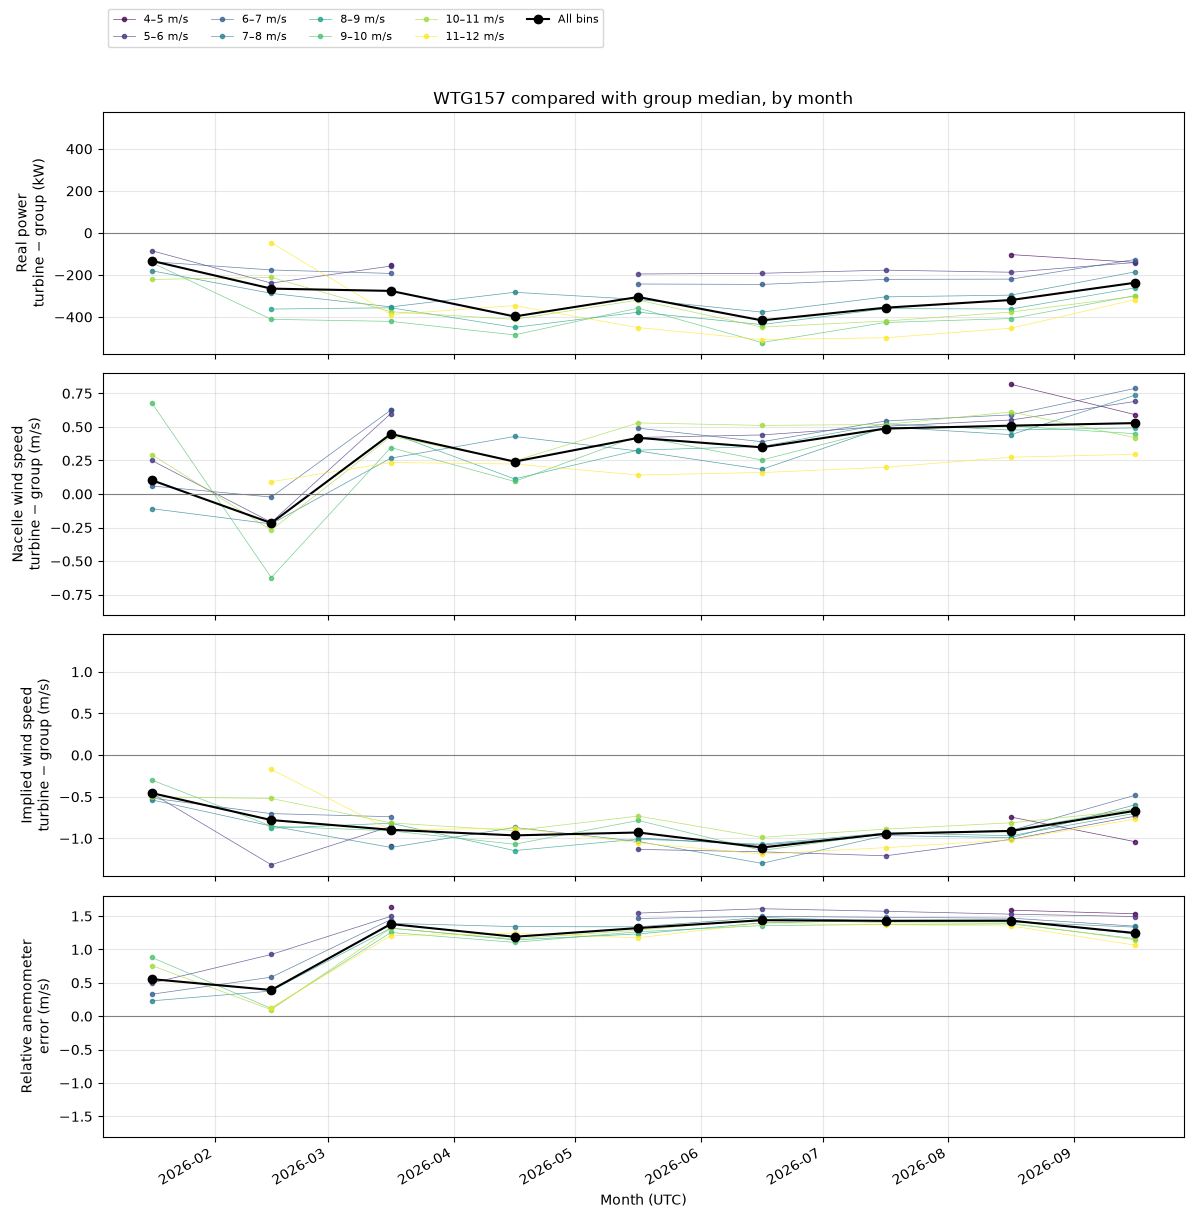

In [99]:
plot_vs_group(result, 'WTG157', bins = None, min_n = 30, show_bins = True)

In [117]:
def plot_vs_group(m, turbine, bins = None, min_n = 30, show_bins = True, pad = 1.1):
    def summarise(df, keys):
        out = (df.groupby(keys, observed = True)
                 .agg(n = ('ws_rel', 'size'),
                      ws_rel = ('ws_rel', 'median'),
                      diff_power = ('diff_power', 'median'),
                      ref_diff_power = ('ref_diff_power', 'median'),
                      sum_power = ('KPI_real_power_ac', 'sum'),
                      sum_ref_power = ('ref_power', 'sum'))
                 .reset_index())
        out['power_ratio'] = out['sum_power'] / out['sum_ref_power'].replace(0, np.nan)
        out.loc[out['n'] < min_n, ['ws_rel', 'diff_power', 'ref_diff_power', 'power_ratio']] = np.nan
        return out

    by_bin = summarise(m, ['month', 'ref_bin'])
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]
    overall = summarise(m, ['month'])

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_ratio', 'Power ratio\nturbine / group', 1),
              ('ws_rel', 'Nacelle wind speed\nturbine − group (m/s)', 0),
              ('diff_power', 'Nacelle − implied\nwind speed (m/s)', 0)]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (12, 10), sharex = True)
    for ax, (col, label, baseline) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 1, alpha = 0.5, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = 'black', lw = 2.5, marker = 'o', label = f'{turbine}, all bins')

        vals = [overall[col]]
        if show_bins:
            vals.append(by_bin[col])

        # group's own nacelle − implied, for comparison
        if col == 'diff_power':
            ax.plot(overall['x'], overall['ref_diff_power'], color = 'black', lw = 1.5, ls = '--',
                    marker = 's', ms = 4, label = 'Group median, all bins')
            ax.legend(fontsize = 8, loc = 'upper right')
            vals.append(overall['ref_diff_power'])

        ax.axhline(baseline, color = 'gray', lw = 0.8, ls = ':')
        ax.set_ylabel(label)
        ax.grid(alpha = 0.3)

        # symmetric limits around the baseline, from the largest value drawn
        v = pd.concat(vals).to_numpy(dtype = float)
        lim = np.nanmax(np.abs(v - baseline)) if np.isfinite(v).any() else np.nan
        if np.isfinite(lim) and lim > 0:
            ax.set_ylim(baseline - lim * pad, baseline + lim * pad)

    axes[0].set_title(f'{turbine} compared with group median, by month')
    axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper left', bbox_to_anchor = (0, 1.4))
    axes[-1].set_xlabel('Month (UTC)')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

In [182]:
def plot_vs_group(m, turbine, bins = None, min_n = 30, show_bins = True, pad = 1.1):
    def summarise(df, keys):
        out = (df.groupby(keys, observed = True)
                 .agg(n = ('ws_rel', 'size'),
                      ws_rel = ('ws_rel', 'median'),
                      anem_rel = ('anem_rel', 'median'),
                      sum_power = ('KPI_real_power_ac', 'sum'),
                      sum_ref_power = ('ref_power', 'sum'))
                 .reset_index())
        out['power_ratio'] = out['sum_power'] / out['sum_ref_power'].replace(0, np.nan)
        out.loc[out['n'] < min_n, ['ws_rel', 'anem_rel', 'power_ratio']] = np.nan
        return out

    by_bin = summarise(m, ['month', 'ref_bin'])
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]
    overall = summarise(m, ['month'])

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_ratio', 'Power Ratio Comparison\nTurbine / Group', 1),
              ('ws_rel', 'Nacelle Wind Speed Comparison\nTurbine − Group (m/s)', 0),
              ('anem_rel', 'Nacelle Difference from Implied\nTurbine − Group (m/s)', 0)]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (12, 10), sharex = True)
    fig.suptitle(f'Turbine {turbine} Analysis of Power and Wind Speed', fontsize = 14)
    for ax, (col, label, baseline) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 0.5, alpha = 0.75, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = '#8FA9C4', lw = 1.5, marker = 'o', label = 'All bins')
        ax.axhline(baseline, color = 'black', lw = 1, ls = '-')
        ax.set_ylabel(label)
        ax.grid(axis = 'y', alpha = 0.3)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)

        # symmetric limits around the baseline, from the largest value drawn
        vals = [overall[col]] + ([by_bin[col]] if show_bins else [])
        v = pd.concat(vals).to_numpy(dtype = float)
        lim = np.nanmax(np.abs(v - baseline)) if np.isfinite(v).any() else np.nan
        if np.isfinite(lim) and lim > 0:
            ax.set_ylim(baseline - lim * pad, baseline + lim * pad)

    axes[0].set_title(f'Comparing {turbine} with group median, by month', fontsize = 12)
    if show_bins:
        axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper right')
    axes[-1].set_xlabel('Month (UTC)')
    axes[-1].tick_params(labelbottom = True)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

In [195]:
def plot_vs_group(m, turbine, bins = None, min_n = 30, show_bins = True, pad = 1.1):
    def summarise(df, keys):
        out = (df.groupby(keys, observed = True)
                 .agg(n = ('ws_rel', 'size'),
                      ws_rel = ('ws_rel', 'median'),
                      anem_rel = ('anem_rel', 'median'),
                      sum_power = ('KPI_real_power_ac', 'sum'),
                      sum_ref_power = ('ref_power', 'sum'))
                 .reset_index())
        out['power_ratio'] = out['sum_power'] / out['sum_ref_power'].replace(0, np.nan)
        out.loc[out['n'] < min_n, ['ws_rel', 'anem_rel', 'power_ratio']] = np.nan
        return out

    by_bin = summarise(m, ['month', 'ref_bin'])
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]
    overall = summarise(m, ['month'])

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_ratio', 'Power Ratio Comparison\nTurbine / Group', 1, (0.9, 1.1)),
              ('ws_rel', 'Nacelle Wind Speed Comparison\nTurbine − Group (m/s)', 0, (-1, 1)),
              ('anem_rel', 'Nacelle Difference from Implied\nTurbine − Group (m/s)', 0, (-1, 1))]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (12, 10), sharex = True)
    fig.suptitle(f'Turbine {turbine} Analysis of Power and Wind Speed', fontsize = 14)
    for ax, (col, label, baseline, ylim) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 0.5, alpha = 0.75, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = '#8FA9C4', lw = 1.5, marker = 'o', label = 'All bins')
        ax.axhline(baseline, color = 'black', lw = 1, ls = '-')
        ax.set_ylabel(label)
        ax.grid(axis = 'y', alpha = 0.3)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)

        # fixed y-axis limits
        ax.set_ylim(*ylim)

    axes[0].set_title(f'Comparing {turbine} with group median, by month', fontsize = 12)
    if show_bins:
        axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper right')
    axes[-1].set_xlabel('Month (UTC)')
    axes[-1].tick_params(labelbottom = True)
    fig.autofmt_xdate()
    fig.tight_layout(h_pad = 2.5)
    plt.show()

In [226]:
def plot_vs_group_auto(m, turbine, bins = None, min_n = 30, show_bins = True, pad = 1.1):
    def summarise(df, keys):
        out = (df.groupby(keys, observed = True)
                 .agg(n = ('ws_rel', 'size'),
                      ws_rel = ('ws_rel', 'median'),
                      implied_rel = ('implied_rel', 'median'),
                      sum_power = ('KPI_real_power_ac', 'sum'),
                      sum_ref_power = ('ref_power', 'sum'))
                 .reset_index())
        out['power_ratio'] = out['sum_power'] / out['sum_ref_power'].replace(0, np.nan)
        out.loc[out['n'] < min_n, ['ws_rel', 'implied_rel', 'power_ratio']] = np.nan
        return out

    by_bin = summarise(m, ['month', 'ref_bin'])
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]
    overall = summarise(m, ['month'])

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_ratio', 'Power Ratio Comparison\nTurbine / Group', 1),
              ('ws_rel', 'Nacelle Wind Speed Comparison\nTurbine − Group (m/s)', 0),
              ('implied_rel', 'Implied Wind Speed Comparison\nTurbine − Group (m/s)', 0)]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (12, 10), sharex = True)
    fig.suptitle(f'Turbine {turbine} Analysis of Power and Wind Speed', fontsize = 14)
    for ax, (col, label, baseline) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 0.5, alpha = 0.75, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = '#8FA9C4', lw = 1.5, marker = 'o', label = 'All bins')
        ax.axhline(baseline, color = 'black', lw = 1, ls = '-')
        ax.set_ylabel(label)
        ax.grid(axis = 'y', alpha = 0.3)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)

        # symmetric limits around the baseline, from the largest value drawn
        vals = [overall[col]] + ([by_bin[col]] if show_bins else [])
        v = pd.concat(vals).to_numpy(dtype = float)
        lim = np.nanmax(np.abs(v - baseline)) if np.isfinite(v).any() else np.nan
        if np.isfinite(lim) and lim > 0:
            ax.set_ylim(baseline - lim * pad, baseline + lim * pad)

    axes[0].set_title(f'Comparing {turbine} with group median, by month', fontsize = 12)
    if show_bins:
        axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper right')
    axes[-1].set_xlabel('Month (UTC)')
    axes[-1].tick_params(labelbottom = True)
    fig.autofmt_xdate()
    fig.tight_layout(h_pad = 2.5)
    plt.show()

In [244]:
def plot_vs_group(m, turbine, bins = None, min_n = 30, show_bins = True, pad = 1.1):
    def summarise(df, keys):
        out = (df.groupby(keys, observed = True)
                 .agg(n = ('ws_rel', 'size'),
                      ws_rel = ('ws_rel', 'median'),
                      implied_rel = ('implied_rel', 'median'),
                      sum_power = ('KPI_real_power_ac', 'sum'),
                      sum_ref_power = ('ref_power', 'sum'))
                 .reset_index())
        out['power_ratio'] = out['sum_power'] / out['sum_ref_power'].replace(0, np.nan)
        out.loc[out['n'] < min_n, ['ws_rel', 'implied_rel', 'power_ratio']] = np.nan
        return out

    by_bin = summarise(m, ['month', 'ref_bin'])
    if bins is not None:
        by_bin = by_bin[by_bin['ref_bin'].apply(lambda iv: iv.left).isin(bins)]
    overall = summarise(m, ['month'])

    # plots each month at its midpoint
    mid = lambda p: p.dt.start_time + (p.dt.end_time - p.dt.start_time) / 2
    by_bin['x'] = mid(by_bin['month'])
    overall['x'] = mid(overall['month'])

    panels = [('power_ratio', 'Power Ratio Comparison\nTurbine / Group', 1, (0.6, 1.4)),
              ('ws_rel', 'Nacelle Wind Speed Comparison\nTurbine − Group (m/s)', 0, (-2, 2)),
              ('implied_rel', 'Implied Wind Speed Comparison\nTurbine − Group (m/s)', 0, (-2, 2))]

    bin_list = sorted(by_bin['ref_bin'].unique(), key = lambda iv: iv.left)
    colors = plt.cm.viridis(np.linspace(0, 1, len(bin_list)))

    fig, axes = plt.subplots(len(panels), 1, figsize = (6, 10), sharex = True)
    fig.suptitle(f'Turbine {turbine} Analysis of Power and Wind Speed', fontsize = 14)
    for ax, (col, label, baseline, ylim) in zip(axes, panels):
        if show_bins:
            for iv, c in zip(bin_list, colors):
                sub = by_bin[by_bin['ref_bin'] == iv]
                ax.plot(sub['x'], sub[col], color = c, lw = 0.5, alpha = 0.75, marker = '.',
                        label = f'{iv.left:g}–{iv.right:g} m/s')
        ax.plot(overall['x'], overall[col], color = '#8FA9C4', lw = 1.5, marker = 'o', label = 'All bins')
        ax.axhline(baseline, color = 'black', lw = 1, ls = '-')
        ax.set_ylabel(label)
        ax.grid(axis = 'y', alpha = 0.3)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)

        # fixed y-axis limits
        ax.set_ylim(*ylim)

    axes[0].set_title(f'Comparing {turbine} with group median, by month', fontsize = 12)
    if show_bins:
        axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper right')
    axes[-1].set_xlabel('Month (UTC)')
    axes[-1].tick_params(labelbottom = True)
    fig.autofmt_xdate()
    fig.tight_layout(h_pad = 2.5)
    plt.show()

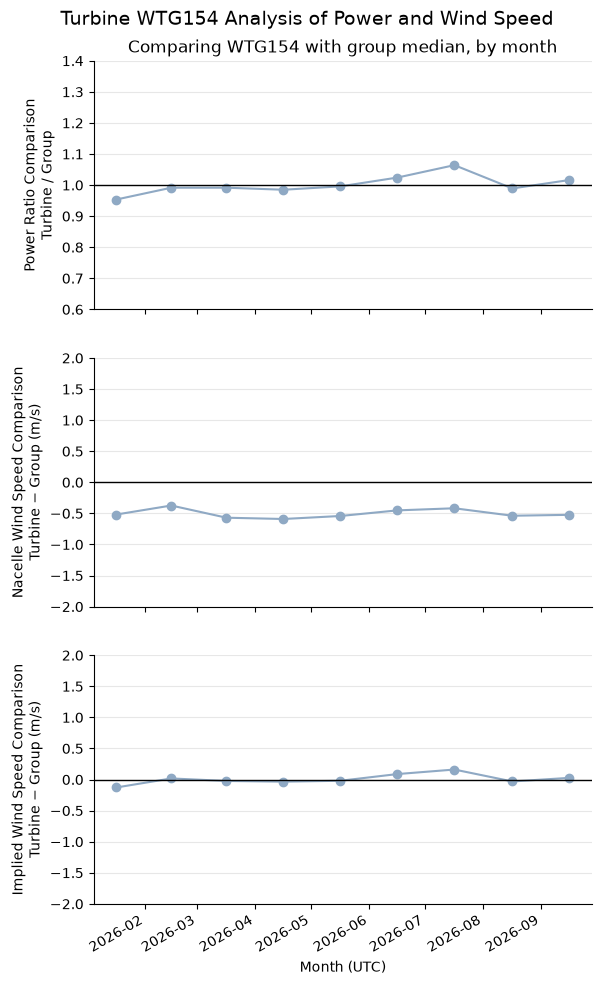

In [245]:
t = 'WTG154'
result2 = wind_speed_analysis_within_group(scada_lowgaus, reference, low = 4, up = 12, group = 1)
result = compare_to_group(result2, t, low = 4, up = 12, min_others = 0)
plot_vs_group(result, t, bins = None, min_n = 30, show_bins = False)

Nacelle Difference from implied group = (Turbine wind speed - Turbine implied wind speeed)-(Group wind speed - Group implied wind speed
= (Turbine wind speed - Group wind speed) - (Turbine implied wind speed - Group implied wind speed)

    axes[0].legend(ncol = 5, fontsize = 8, loc = 'upper left', bbox_to_anchor = (0, 1.4))

In [148]:
result.groupby('month')['implied_rel'].median()

month
2026-01   -0.357617
2026-02   -0.580768
2026-03   -0.515690
2026-04   -0.585869
2026-05   -0.412632
2026-06   -0.414665
2026-07   -0.353609
2026-08   -0.382258
2026-09   -0.211136
Freq: M, Name: implied_rel, dtype: float64

In [47]:
result2 = wind_speed_analysis_within_group(scada_lowgaus, reference, low = 4, up = 12, group = 1)

In [48]:
result2

,utc,month,turbine,group,bin,KPI_real_power_ac,power_ref,wind_speed,ws_implied,air_density,diff_power
0,2026-01-02 06:50:00+00:00,2026-01,WTG150,1,"[4, 5)",4.253560,70.0,4.080824,3.140847,1.083412,0.939977
1,2026-01-02 07:00:00+00:00,2026-01,WTG150,1,"[4, 5)",90.479450,130.0,4.494978,4.205071,0.794519,0.289907
2,2026-01-02 07:10:00+00:00,2026-01,WTG150,1,"[4, 5)",52.544800,63.0,4.010934,3.906650,0.792945,0.104284
3,2026-01-02 07:20:00+00:00,2026-01,WTG150,1,"[5, 6)",1.428193,226.0,5.196293,NaN,1.082034,NaN
4,2026-01-02 08:00:00+00:00,2026-01,WTG150,1,"[4, 5)",11.731491,210.0,4.906677,3.542245,0.794679,1.364432
...,...,...,...,...,...,...,...,...,...,...,...
90327,2026-09-29 06:00:00+00:00,2026-09,WTG156,1,"[11, 12)",2492.860400,2646.0,11.982357,11.298804,1.045364,0.683553
90328,2026-09-29 06:10:00+00:00,2026-09,WTG155,1,"[11, 12)",2190.487300,2408.0,11.199524,10.444035,1.046989,0.755490
90329,2026-09-29 06:10:00+00:00,2026-09,WTG153,1,"[11, 12)",2268.896000,2550.0,11.372173,10.639627,1.034247,0.732546
90330,2026-09-29 06:20:00+00:00,2026-09,WTG155,1,"[11, 12)",2286.791700,2646.0,11.855132,10.685989,1.047334,1.169143


In [50]:
compare_to_others_within_group(result2, 'WTG154', min_n = 0)

,month,bin,turbine_ws_median,others_ws_median,delta_ws_median,turbine_ws_std,others_ws_std,turbine_power_median,others_power_median,delta_power_median,turbine_power_std,others_power_std,turbine_n,others_n,others_n_turbines
0,2026-01,"[4, 5)",4.523536,4.545917,-0.022381,0.256881,0.287020,191.71996,146.836510,44.883450,65.135513,78.928783,22,348,9
1,2026-01,"[5, 6)",5.354167,5.533084,-0.178918,0.256678,0.282826,365.02840,305.173235,59.855165,113.768434,97.047337,23,398,9
2,2026-01,"[6, 7)",6.552696,6.515520,0.037175,0.292435,0.291589,693.32175,551.327600,141.994150,144.428428,137.425767,38,315,9
3,2026-01,"[7, 8)",7.330595,7.448066,-0.117471,0.271206,0.296445,995.67283,834.376475,161.296355,191.037030,175.585181,32,316,9
4,2026-01,"[8, 9)",8.440975,8.495089,-0.054114,0.252890,0.294056,1499.42910,1279.681000,219.748100,152.270323,208.669726,19,272,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,2026-09,"[7, 8)",7.527370,7.521202,0.006167,0.294559,0.292344,914.42450,787.782525,126.641975,129.520457,171.516496,249,1730,9
68,2026-09,"[8, 9)",8.480536,8.480288,0.000247,0.297227,0.288941,1258.98630,1109.968850,149.017450,150.210814,213.559040,271,1770,9
69,2026-09,"[9, 10)",9.498424,9.519088,-0.020664,0.312920,0.289687,1670.96065,1470.619100,200.341550,155.722990,248.996940,258,1711,9
70,2026-09,"[10, 11)",10.497811,10.500126,-0.002316,0.293707,0.290041,1997.32970,1856.777100,140.552600,128.027947,282.262322,257,1813,9


In [234]:
result = wind_speed_analysis(scada_lowgaus, reference, metmasts_clean, low = 4, up = 12, group = 1)

In [235]:
result

,utc,month,turbine,group,bin,KPI_real_power_ac,power_ref,wind_speed,mm_wind_speed,ws_implied,diff_mm,diff_power
0,2026-01-16 14:50:00+00:00,2026-01,WTG159,1,"[4, 5)",19.101963,2.0,3.010779,4.663077,3.587086,-1.652298,-0.576307
1,2026-01-19 11:20:00+00:00,2026-01,WTG151,1,"[5, 6)",89.687570,130.0,4.339530,5.670149,4.199161,-1.330620,0.140369
2,2026-01-19 11:20:00+00:00,2026-01,WTG158,1,"[5, 6)",7.208016,63.0,4.142098,5.670149,3.501857,-1.528052,0.640240
3,2026-01-19 11:20:00+00:00,2026-01,WTG159,1,"[5, 6)",175.426500,210.0,5.081362,5.670149,4.783916,-0.588788,0.297446
4,2026-01-19 11:30:00+00:00,2026-01,WTG159,1,"[6, 7)",237.384340,210.0,5.048991,6.856923,5.152135,-1.807932,-0.103144
...,...,...,...,...,...,...,...,...,...,...,...,...
94737,2026-09-29 05:30:00+00:00,2026-09,WTG150,1,"[11, 12)",2745.843300,2844.0,14.177075,11.520588,NaN,2.656487,NaN
94738,2026-09-29 05:30:00+00:00,2026-09,WTG153,1,"[11, 12)",2531.839800,2646.0,11.853912,11.520588,11.436056,0.333324,0.417856
94739,2026-09-29 05:30:00+00:00,2026-09,WTG152,1,"[11, 12)",2693.465600,2834.0,13.997253,11.520588,NaN,2.476665,NaN
94740,2026-09-29 05:30:00+00:00,2026-09,WTG151,1,"[11, 12)",1508.375400,2779.0,13.236762,11.520588,8.970633,1.716174,4.266129


In [33]:
compare_to_others(result, 'WTG154', min_n = 0)

,month,bin,turbine_ws_median,others_ws_median,delta_ws_median,turbine_ws_std,others_ws_std,turbine_power_median,others_power_median,delta_power_median,turbine_power_std,others_power_std,turbine_diff_mm_median,others_diff_mm_median,delta_diff_mm_median,turbine_diff_mm_std,others_diff_mm_std,turbine_n,others_n,others_n_turbines
0,2026-01,"[4, 5)",3.409122,4.707806,-1.298684,0.907913,1.085463,75.18409,167.60254,-92.41845,103.063237,194.149474,-1.209108,0.220217,-1.429325,0.952478,1.046788,8,118,9
1,2026-01,"[5, 6)",4.690031,5.355283,-0.665252,1.278101,1.448152,249.64845,338.33133,-88.68288,178.895463,295.430744,-0.898453,-0.078453,-0.820000,1.323648,1.485468,13,101,9
2,2026-01,"[6, 7)",5.988047,6.569769,-0.581722,1.508420,1.224992,503.16766,525.42420,-22.25654,293.436887,341.586047,-0.859465,-0.179068,-0.680397,1.554658,1.255523,16,153,9
3,2026-01,"[7, 8)",6.267947,6.992682,-0.724735,1.136573,1.578527,538.92070,656.08167,-117.16097,235.059190,431.361349,-1.120305,-0.574906,-0.545399,1.202430,1.569432,23,215,9
4,2026-01,"[8, 9)",7.127885,7.392326,-0.264441,1.031080,1.270588,840.10834,807.83215,32.27619,266.556019,394.204746,-1.523646,-1.108849,-0.414797,0.967798,1.284880,21,178,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,2026-09,"[7, 8)",6.751859,7.295213,-0.543354,0.574598,1.189480,642.14780,665.36487,-23.21707,145.826563,344.500712,-0.771415,-0.191863,-0.579552,0.503814,1.131453,238,1871,9
68,2026-09,"[8, 9)",7.772286,8.472494,-0.700209,0.575548,1.401838,984.75430,1050.39890,-65.64460,167.188702,453.884030,-0.762149,-0.020725,-0.741424,0.499973,1.366596,269,2144,9
69,2026-09,"[9, 10)",8.705464,9.559249,-0.853785,0.584635,1.423256,1330.68180,1407.19620,-76.51440,199.636497,479.476740,-0.782357,0.094715,-0.877072,0.511444,1.402551,267,2140,9
70,2026-09,"[10, 11)",9.863294,10.674035,-0.810741,0.626223,1.608212,1770.08300,1849.25260,-79.16960,202.539634,518.624911,-0.654155,0.205308,-0.859463,0.553486,1.578322,281,2159,9


In [236]:
summary = bin_summary(result)

In [237]:
summary

,turbine,bin,n,median_diff_mm,median_diff_power,n_power,median_power_ratio
0,WTG150,"[4, 5)",902,-0.386757,-0.200658,884,1.300753
1,WTG150,"[5, 6)",1122,-0.330344,-0.077820,1107,1.067915
2,WTG150,"[6, 7)",1518,-0.045113,0.003948,1497,0.991063
3,WTG150,"[7, 8)",1951,0.296780,0.132581,1930,0.941251
4,WTG150,"[8, 9)",2096,0.784493,0.448425,2056,0.887438
...,...,...,...,...,...,...,...
75,WTG159,"[7, 8)",916,-0.397221,0.107692,907,0.950531
76,WTG159,"[8, 9)",1150,-0.002396,0.277718,1129,0.910399
77,WTG159,"[9, 10)",1239,0.048629,0.461045,1178,0.895211
78,WTG159,"[10, 11)",1389,0.097482,0.667836,1246,0.895762


In [238]:
flags = flag_anemometer_bias(summary)

In [239]:
flags

,turbine,flag,n_bins,off_power,rel_off_power,slope_power,rel_slope_power,off_mm,rel_off_mm,ratio,rel_ratio
0,WTG154,anemometer offset,5,-0.307622,-0.420527,0.085828,-0.015403,-0.856813,-0.686530,1.165207,0.215574
1,WTG156,"location (different wind, anemometer OK)",5,-0.090779,-0.203683,0.076076,-0.025155,-1.107534,-0.937251,1.056041,0.106407
2,WTG151,anemometer scaling / performance varies with w...,5,-0.025661,-0.138566,0.212828,0.111597,0.285099,0.455382,1.010493,0.060859
3,WTG158,"location (different wind, anemometer OK)",5,0.009200,-0.103705,0.105493,0.004262,-0.817786,-0.647502,0.987669,0.038036
4,WTG150,anemometer scaling / performance varies with w...,5,0.132581,0.019676,0.226931,0.125700,0.296780,0.467064,0.941251,-0.008383
5,WTG152,anemometer scaling / performance varies with w...,5,0.180845,0.067940,0.225389,0.124158,0.431363,0.601646,0.932038,-0.017596
6,WTG155,anemometer scaling / performance varies with w...,5,0.269944,0.157040,0.045228,-0.056002,-0.488456,-0.318172,0.855807,-0.093827
7,WTG157,possible underperformance,5,1.449767,1.336862,0.069971,-0.031260,0.177495,0.347778,0.511082,-0.438551
8,WTG159,ok,5,0.107692,-0.005212,0.132912,0.031681,-0.350727,-0.180443,0.950531,0.000898
9,WTG153,ok,5,0.118117,0.005212,0.096968,-0.004262,0.010160,0.180443,0.948736,-0.000898


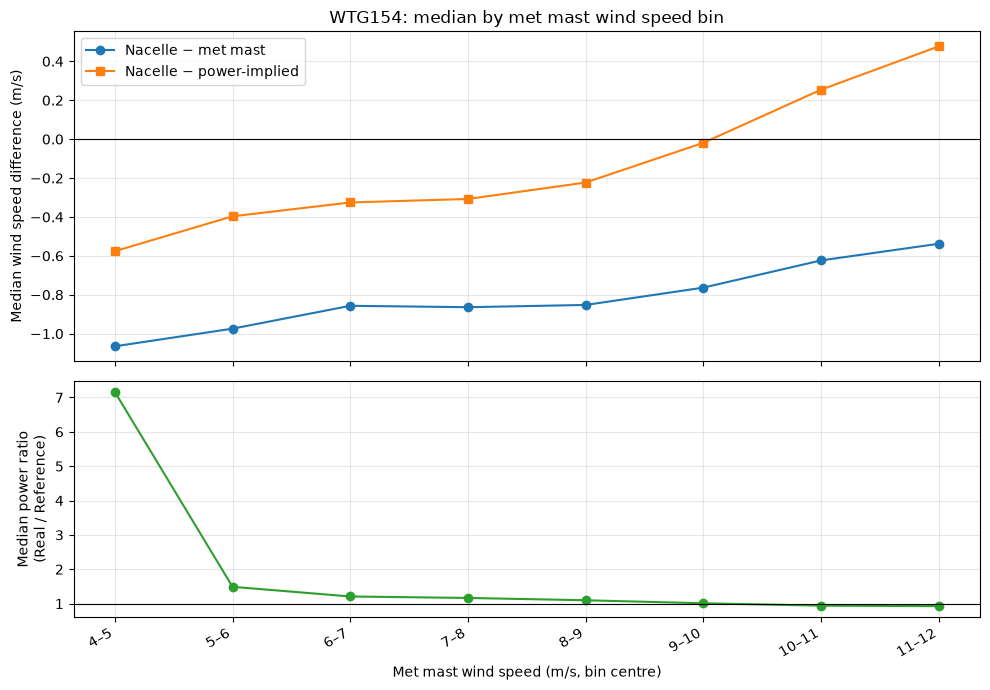

In [240]:
plot_bin_summary(summary, 'WTG154', ylim_diff = None, ylim_ratio = None)

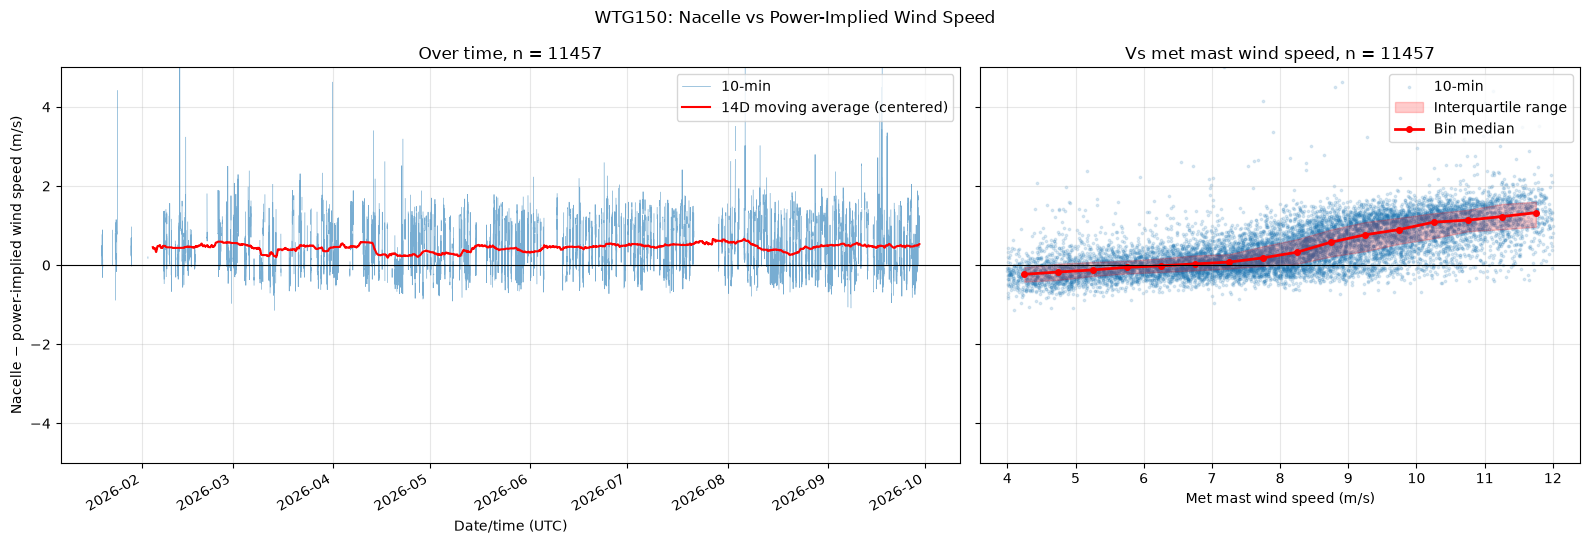

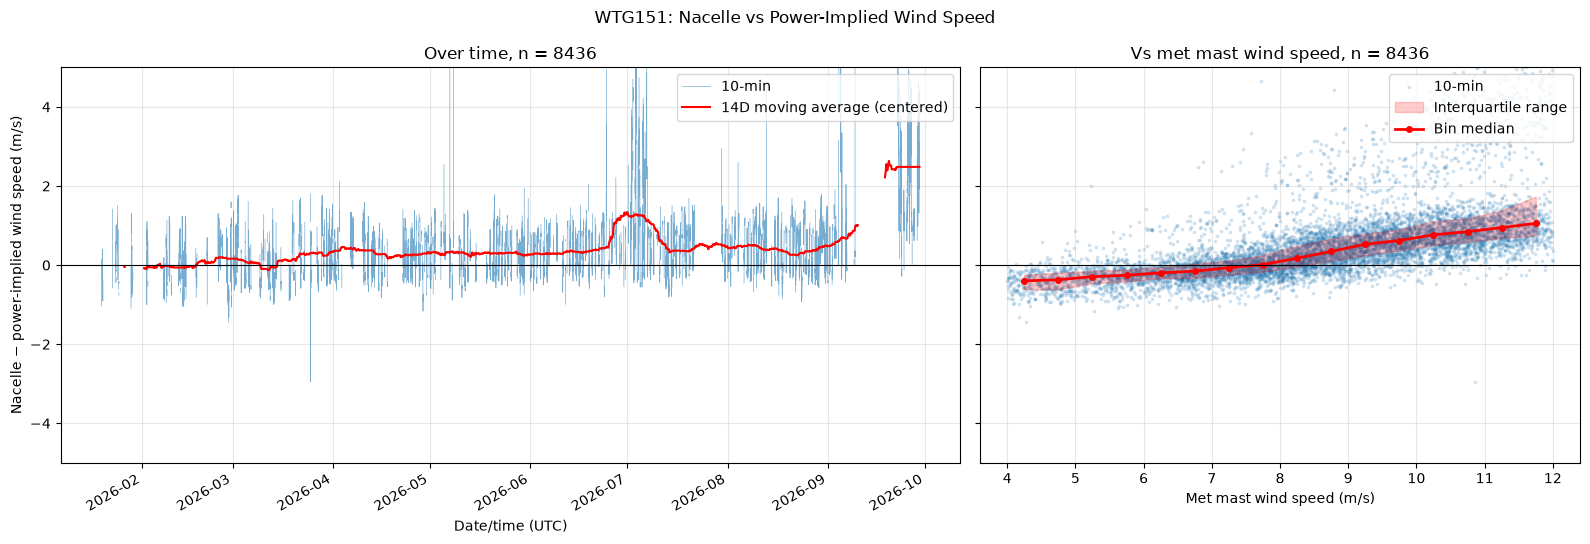

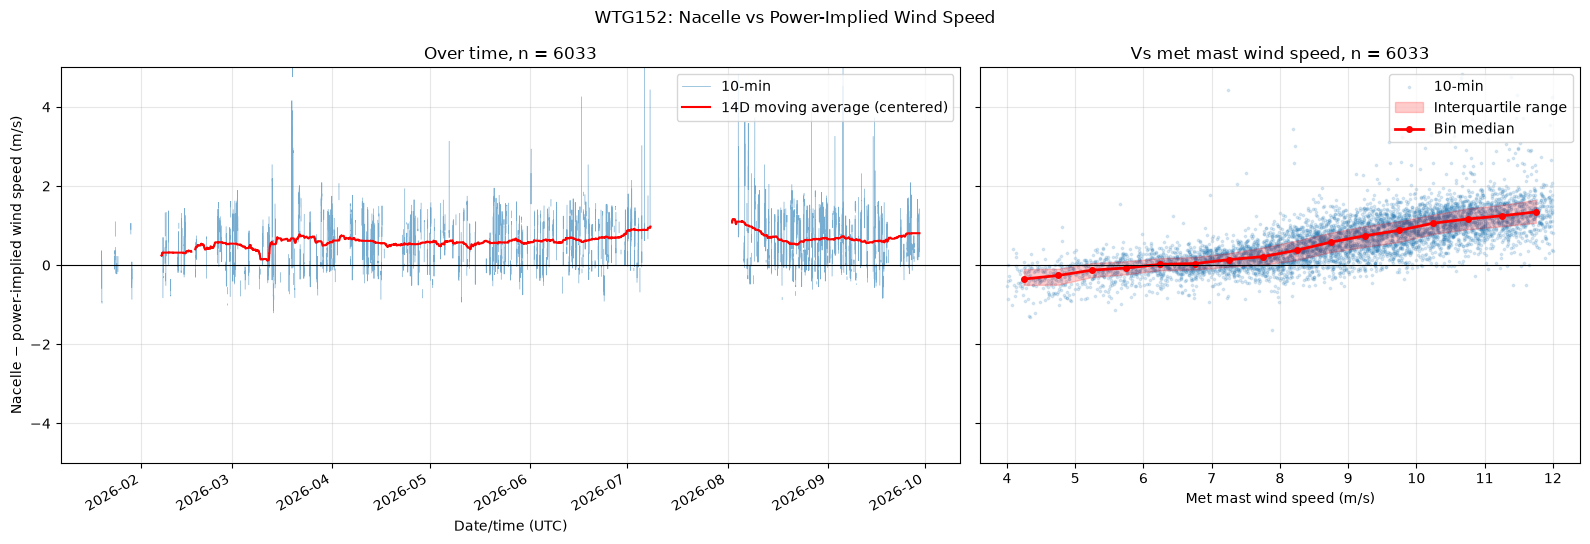

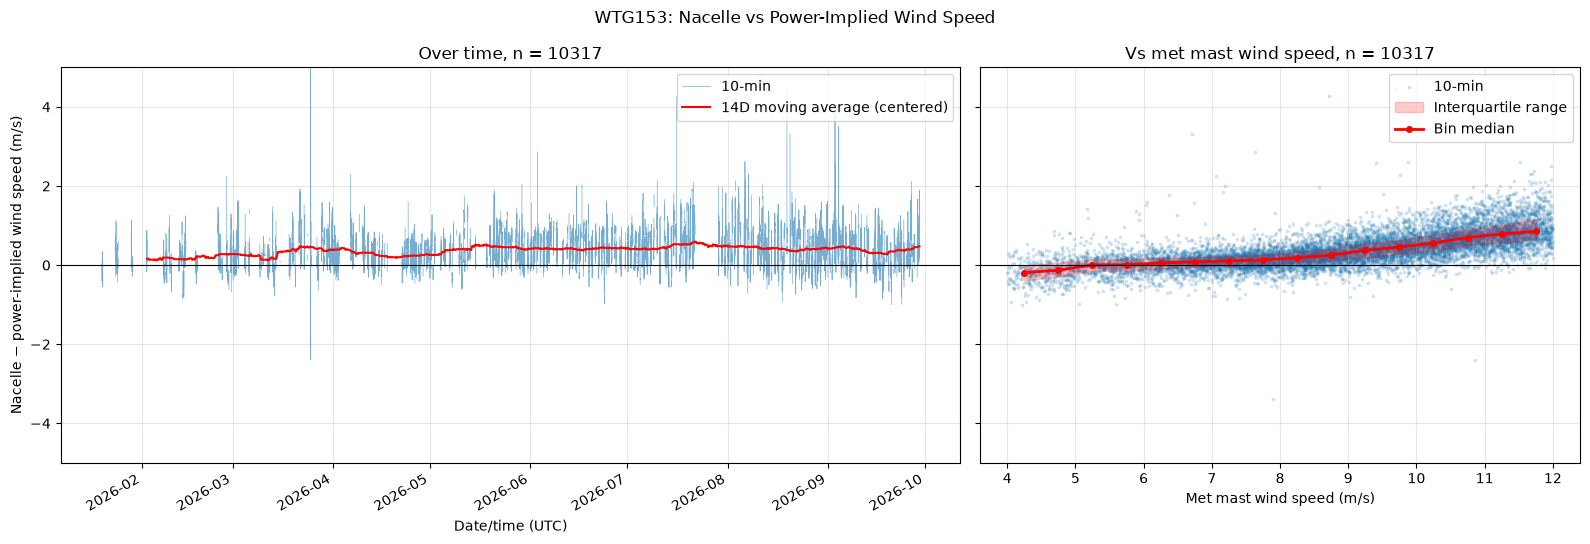

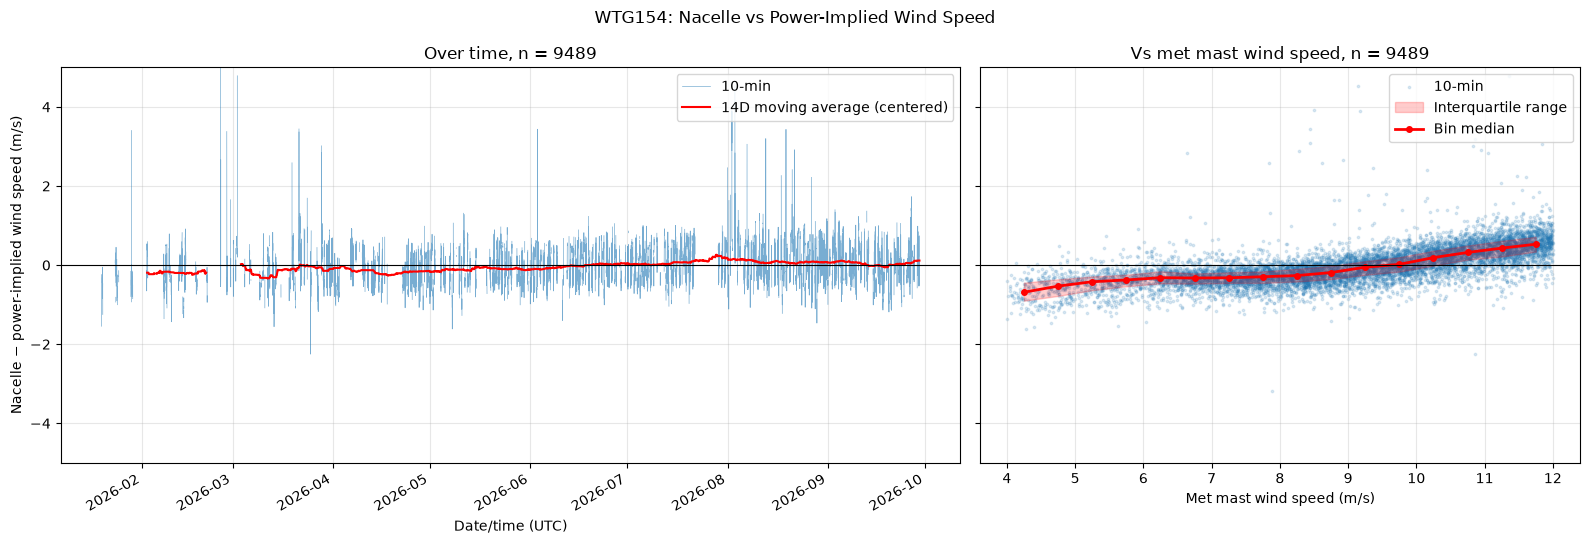

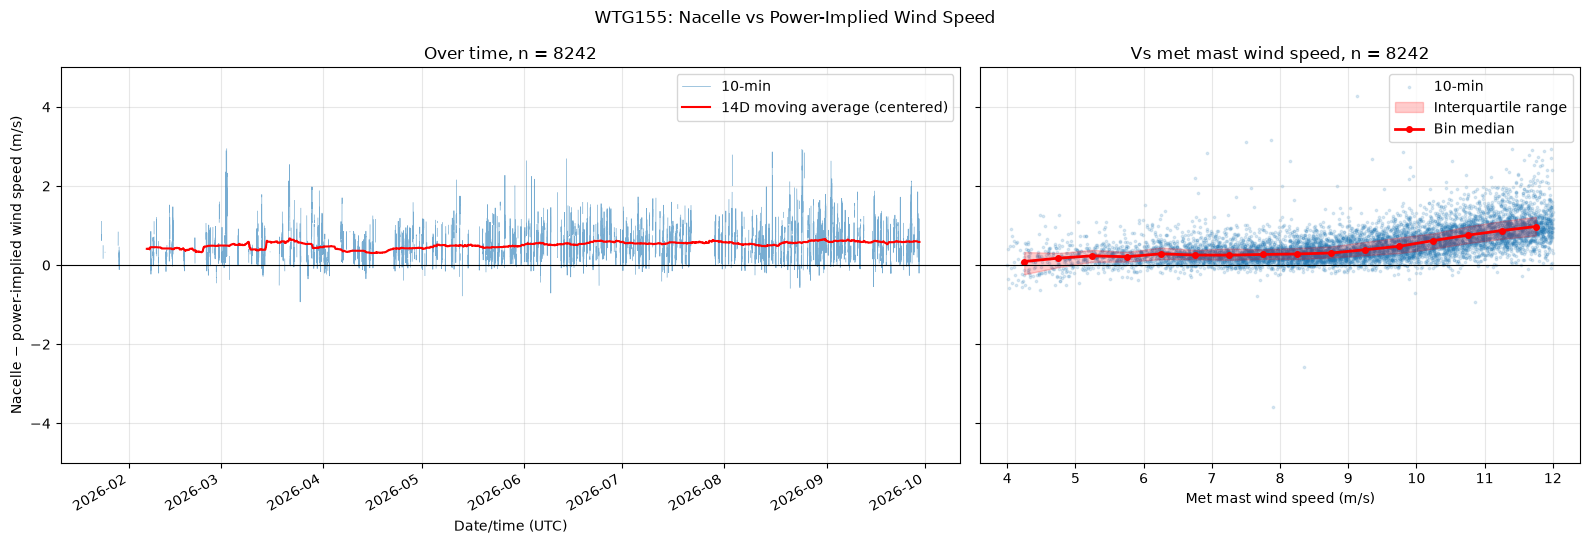

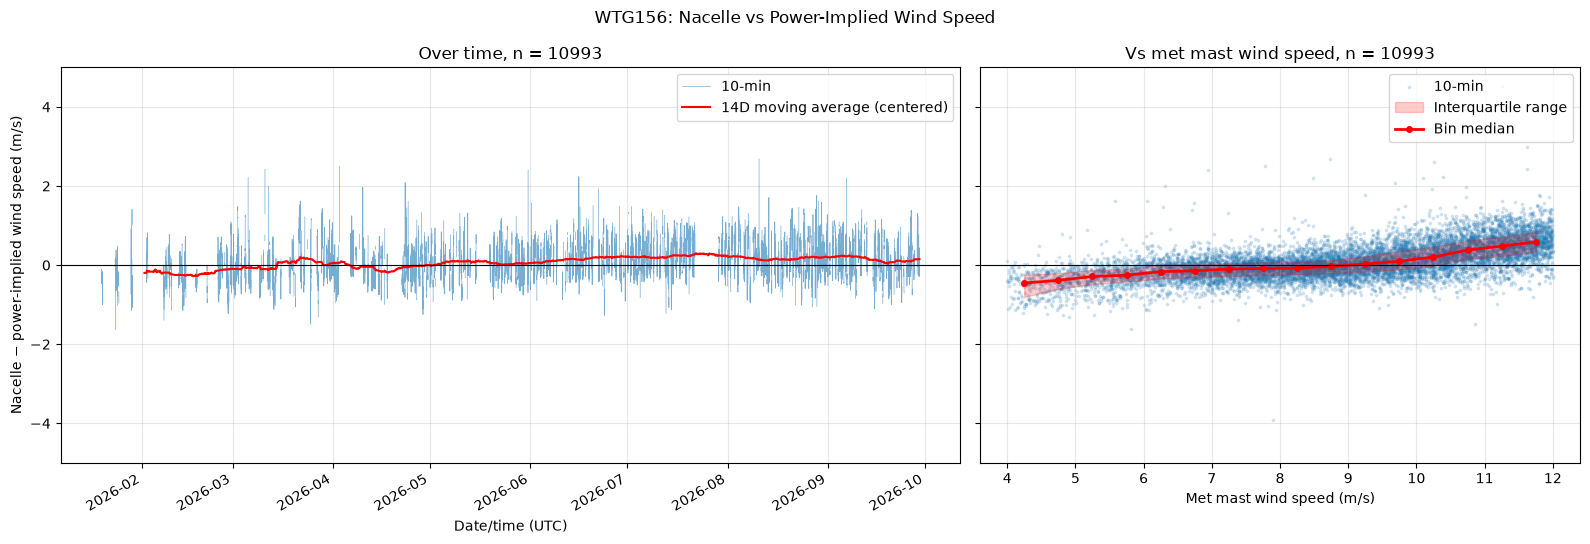

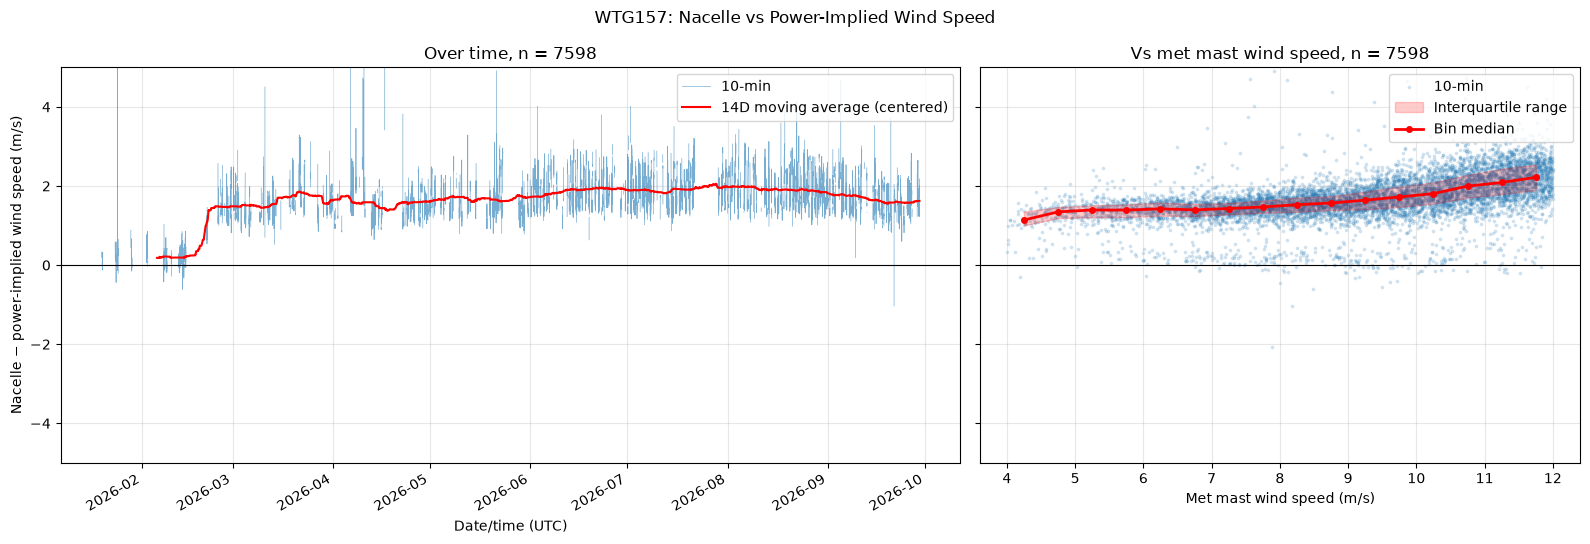

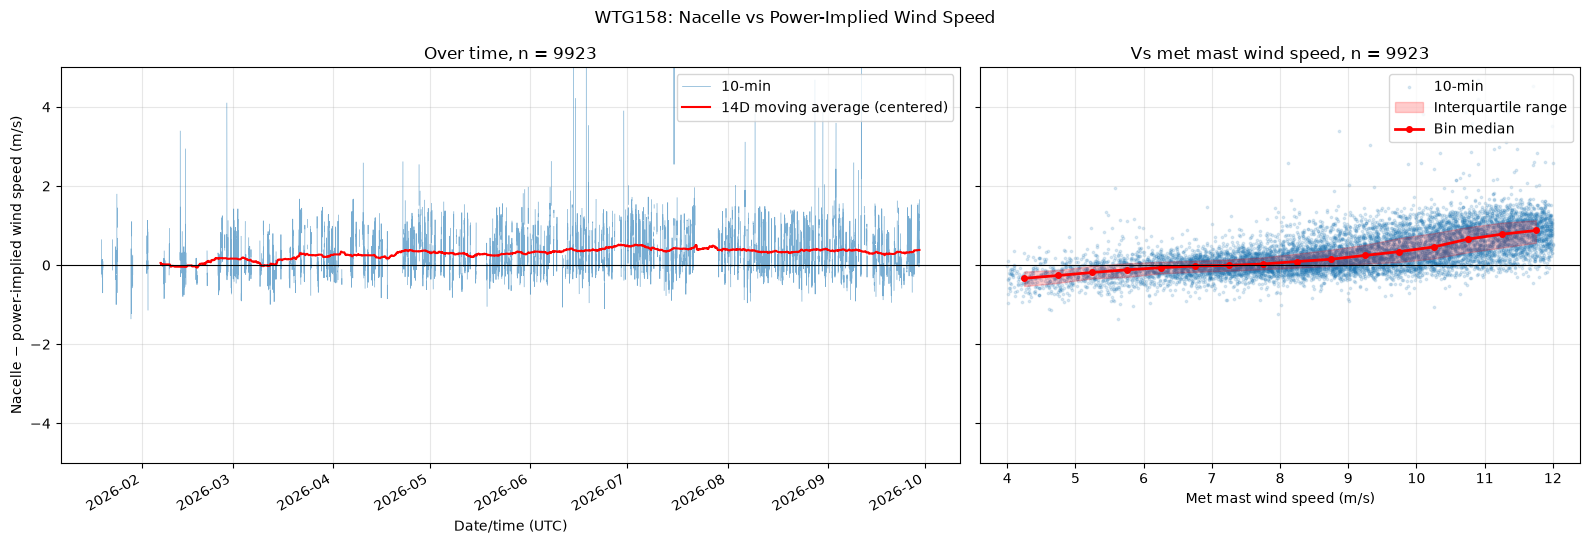

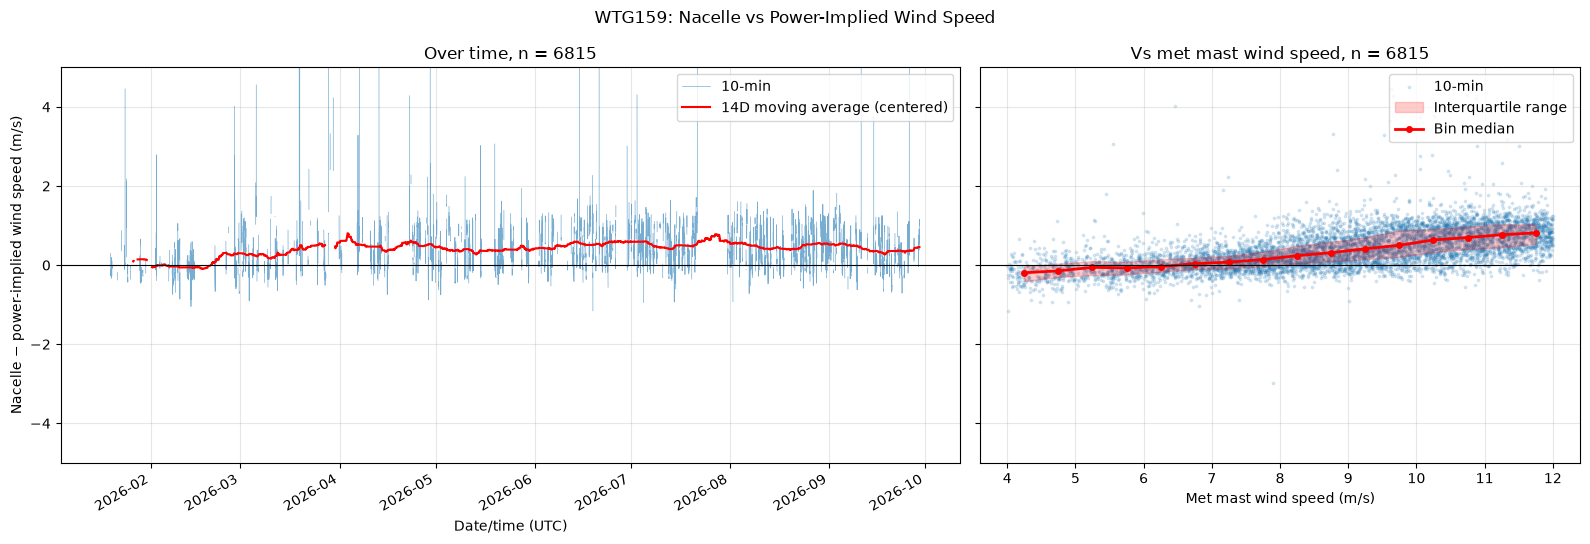

In [39]:
for t in one:
    plot_turbine_diff_power(result, t)

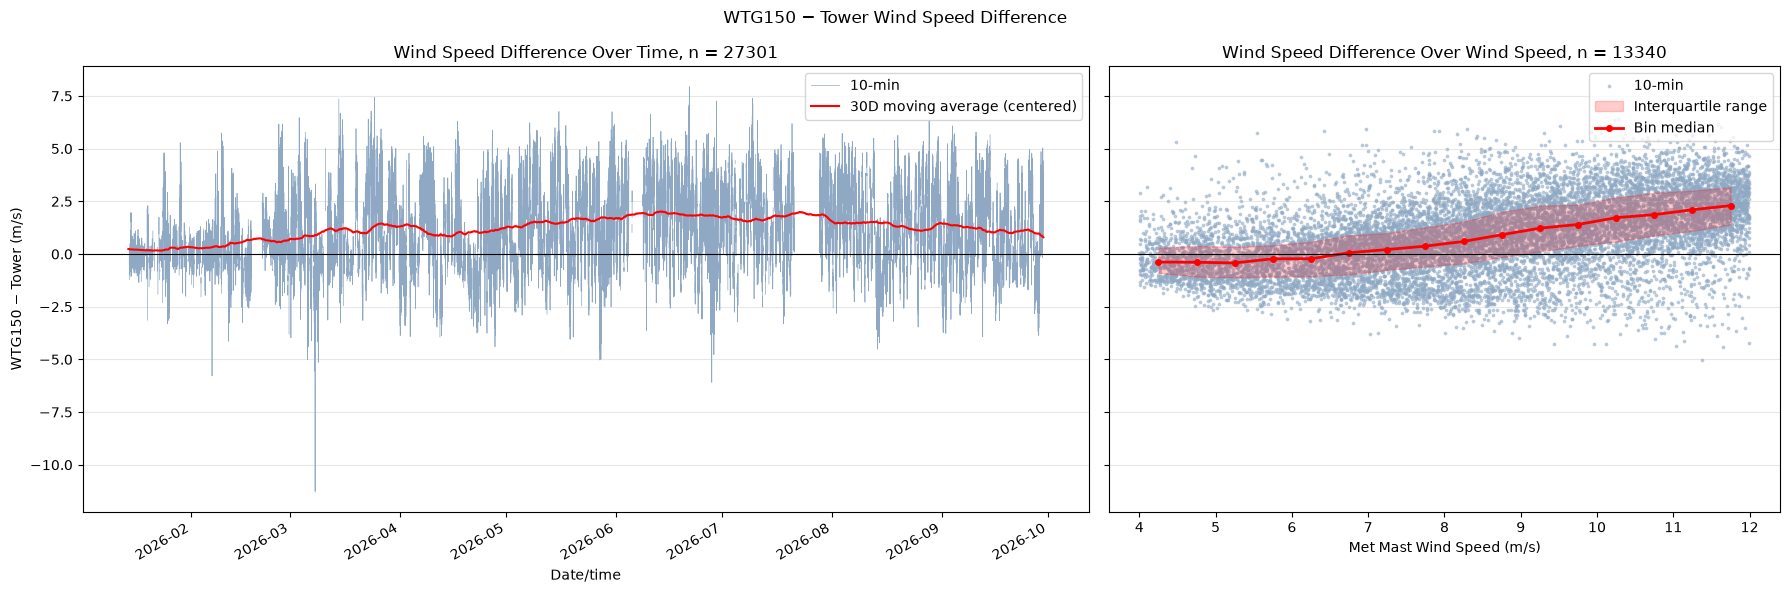

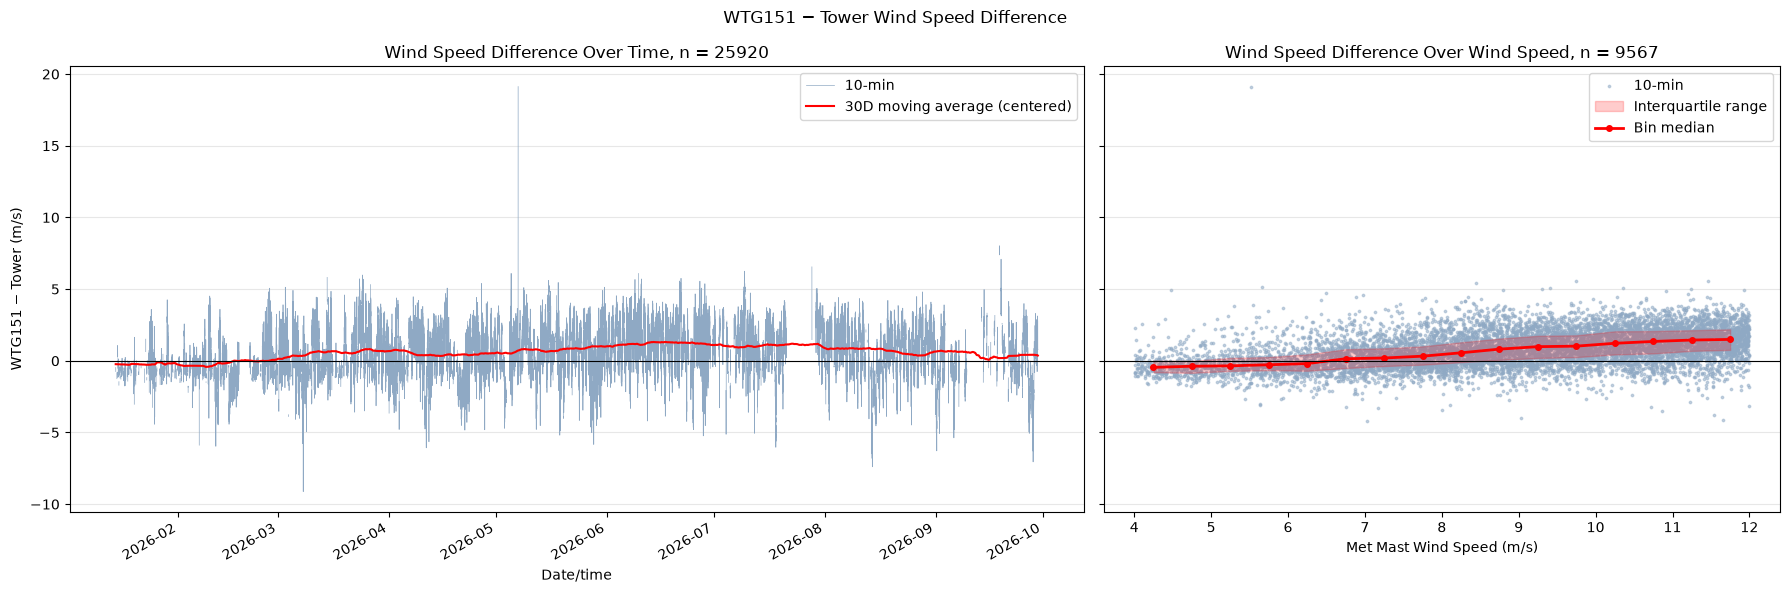

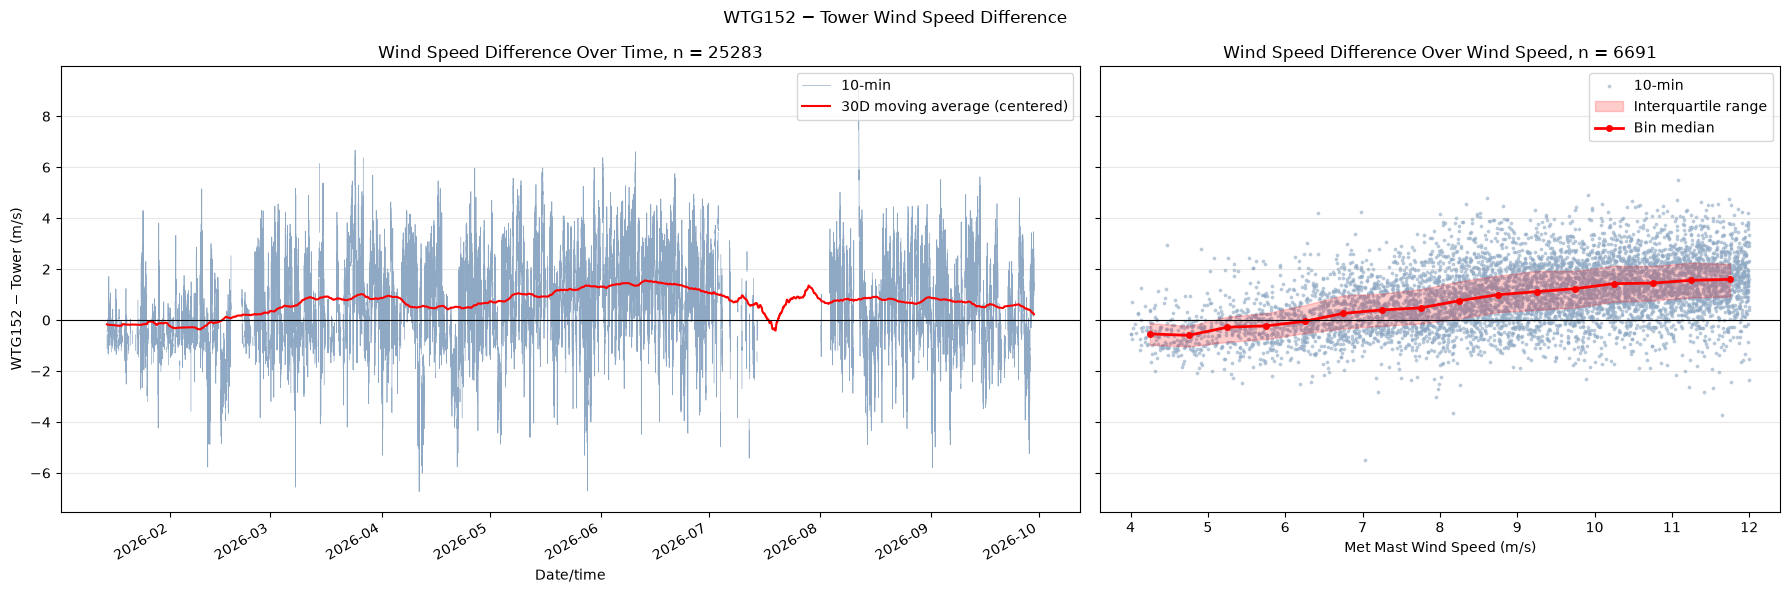

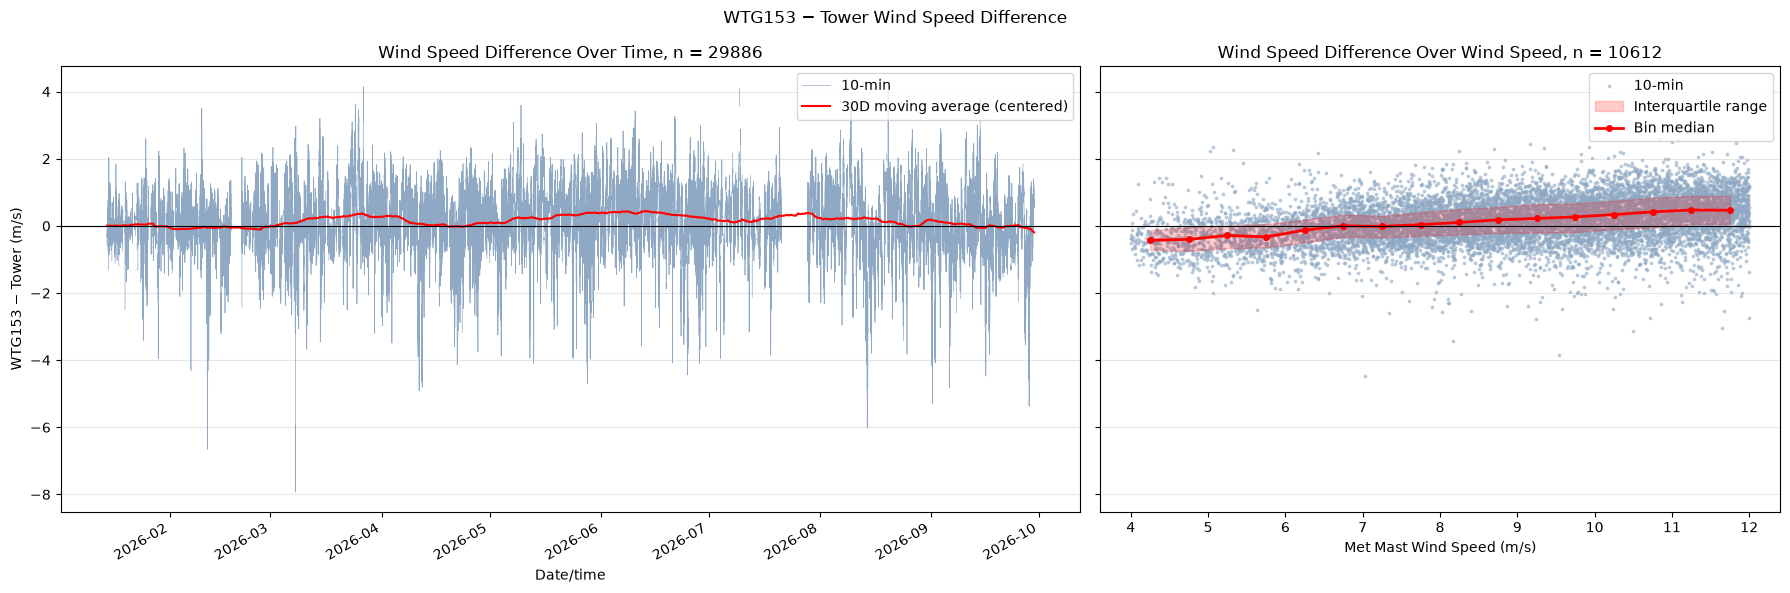

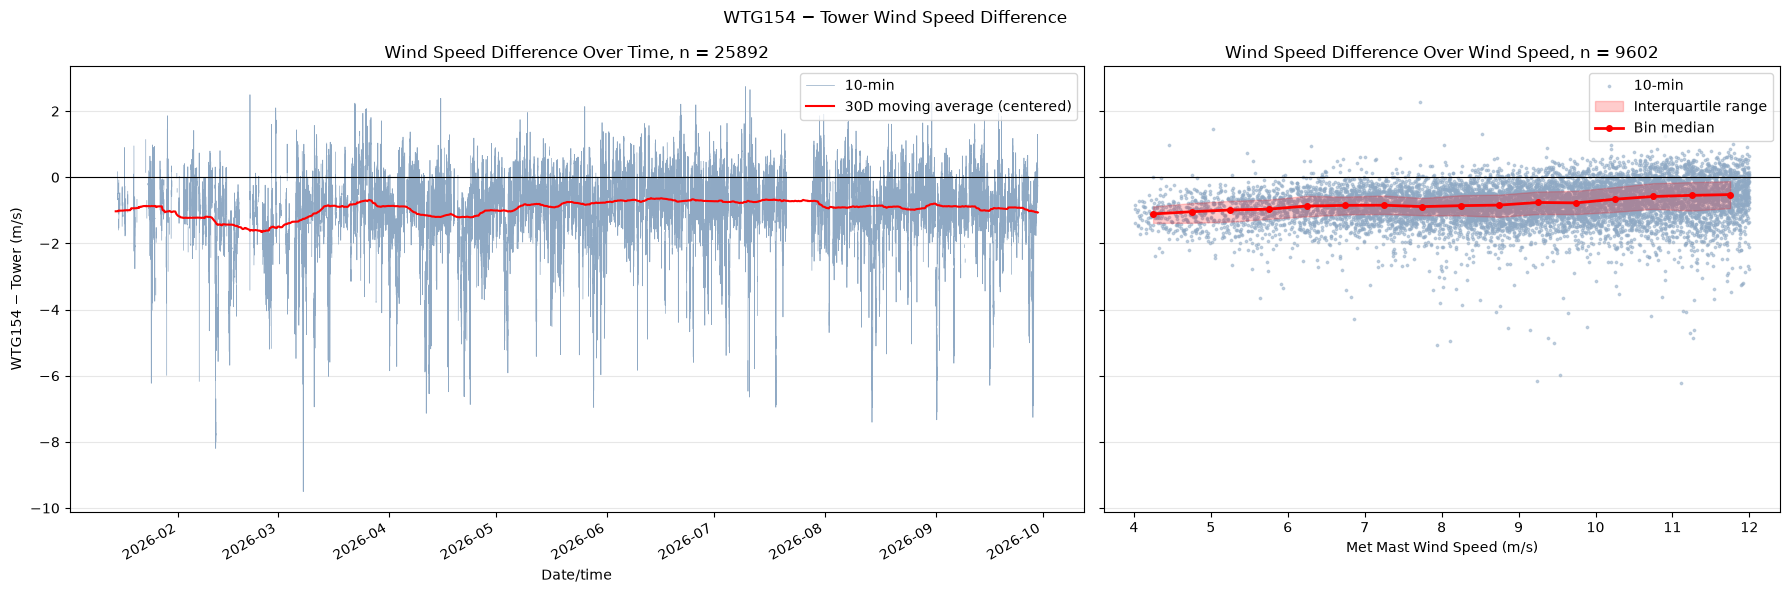

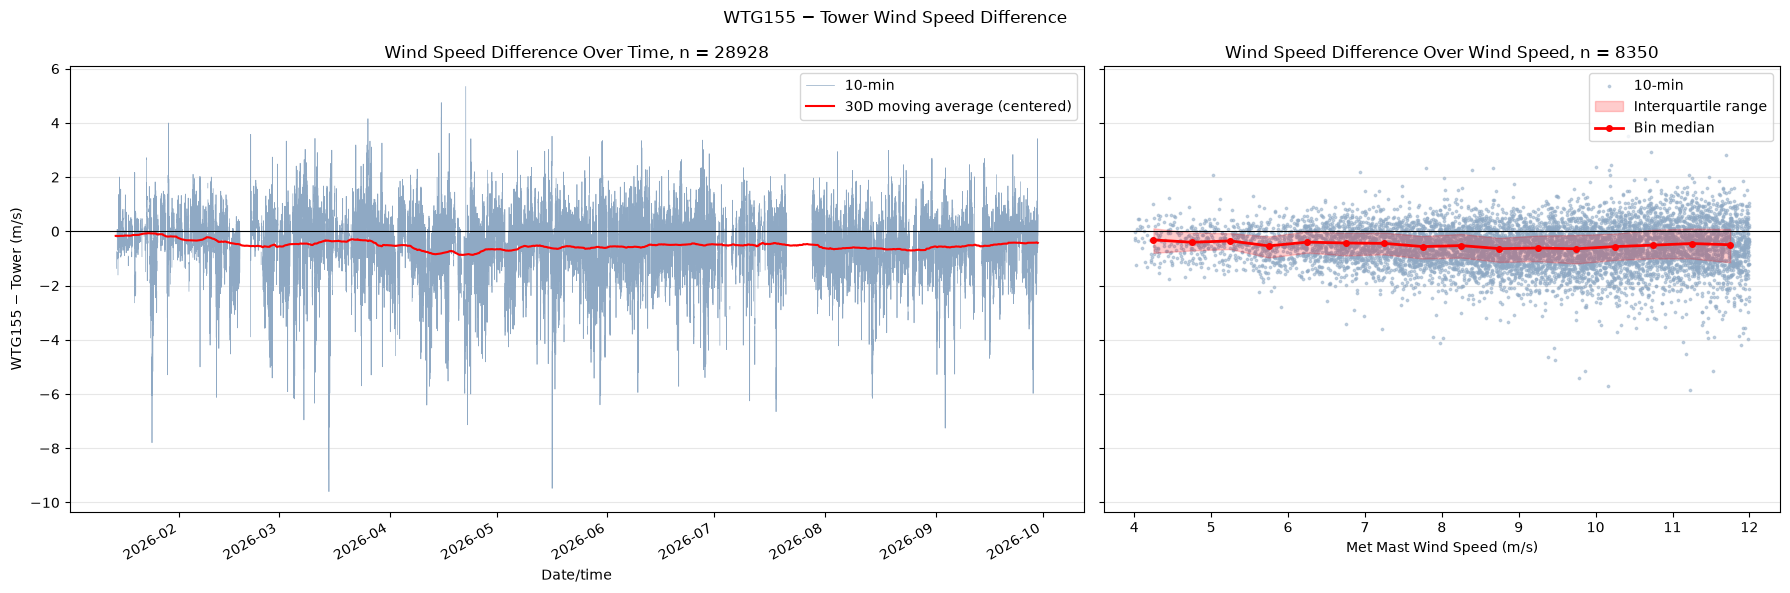

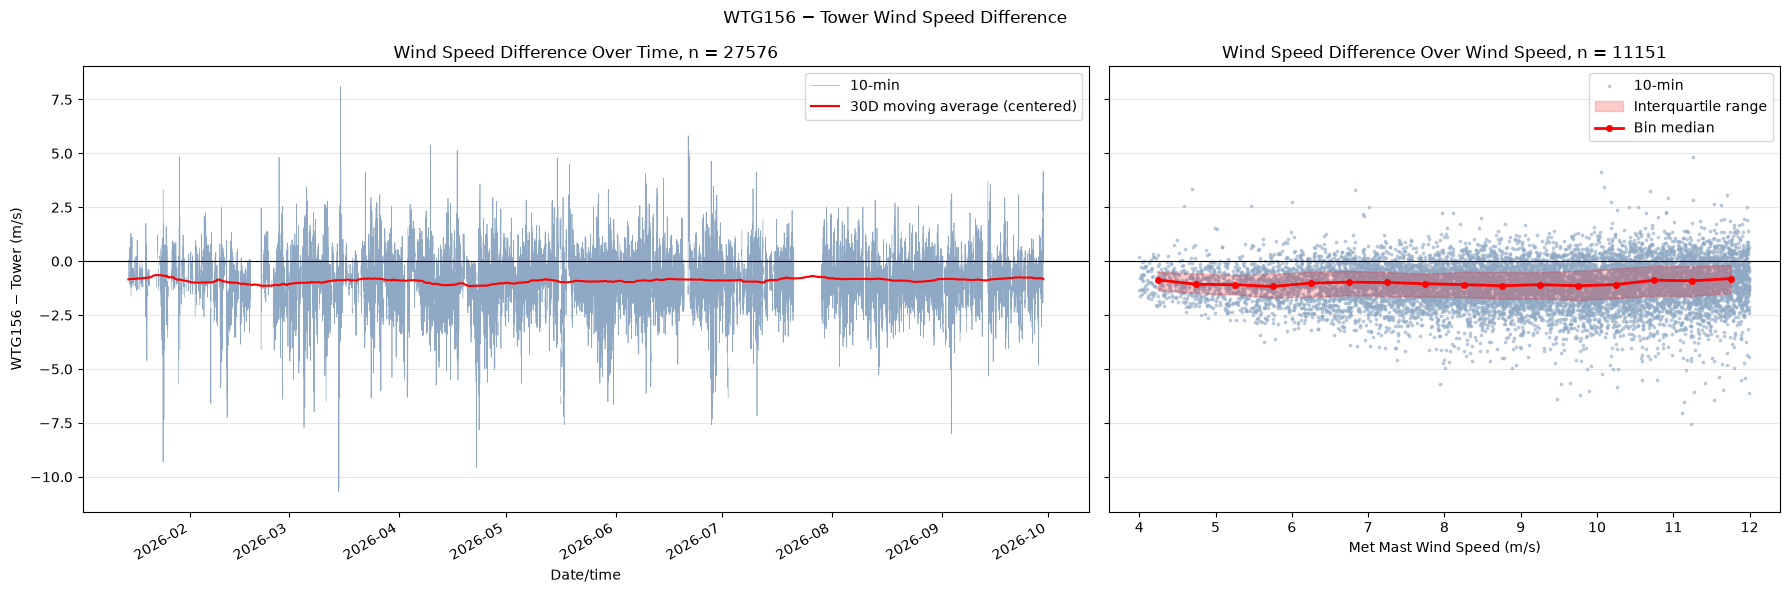

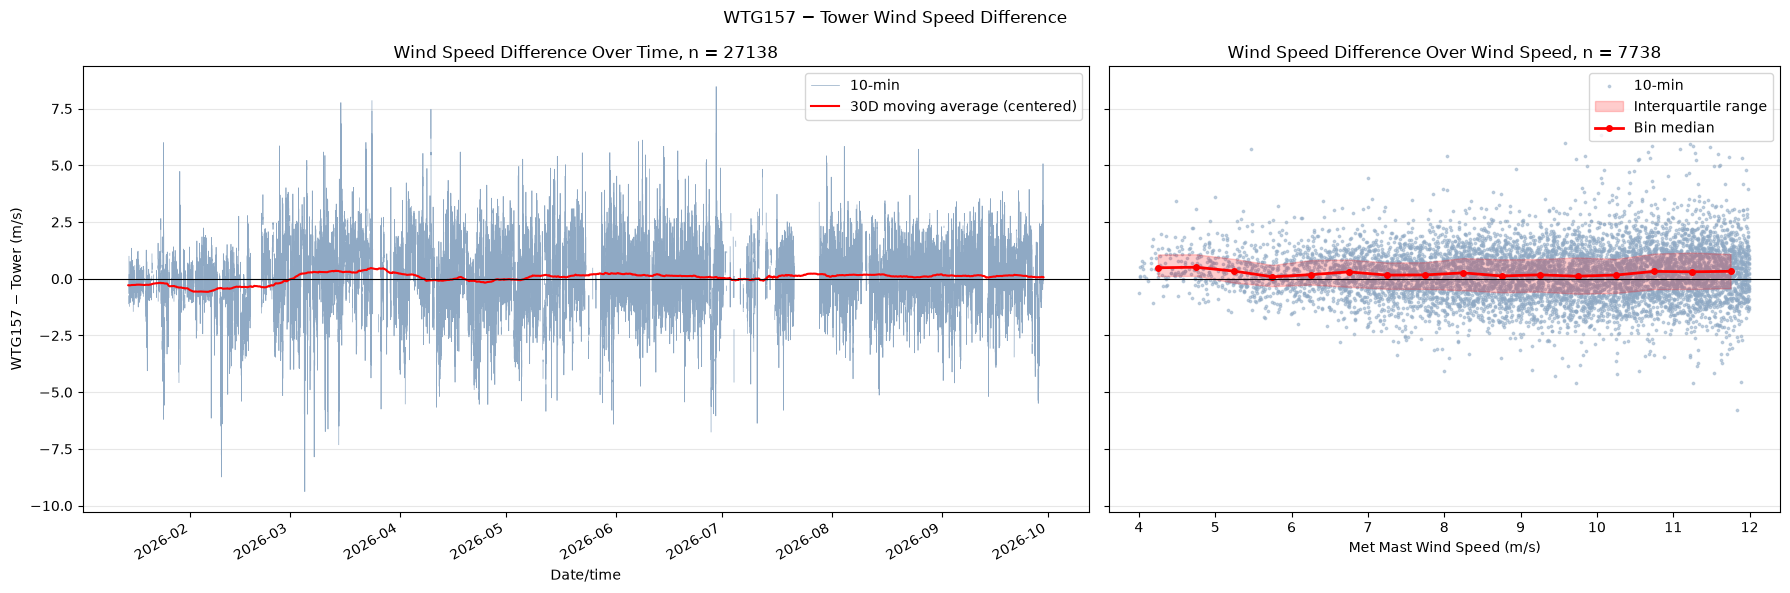

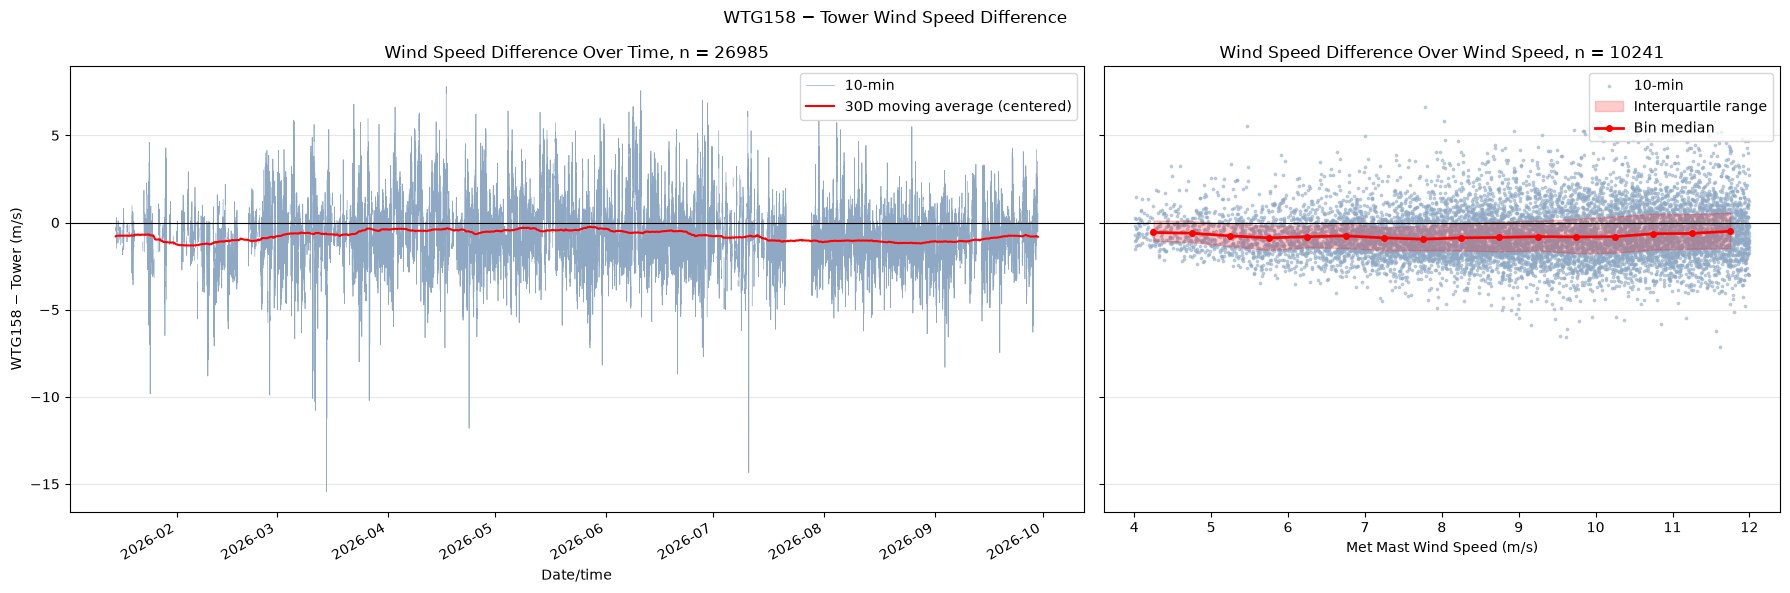

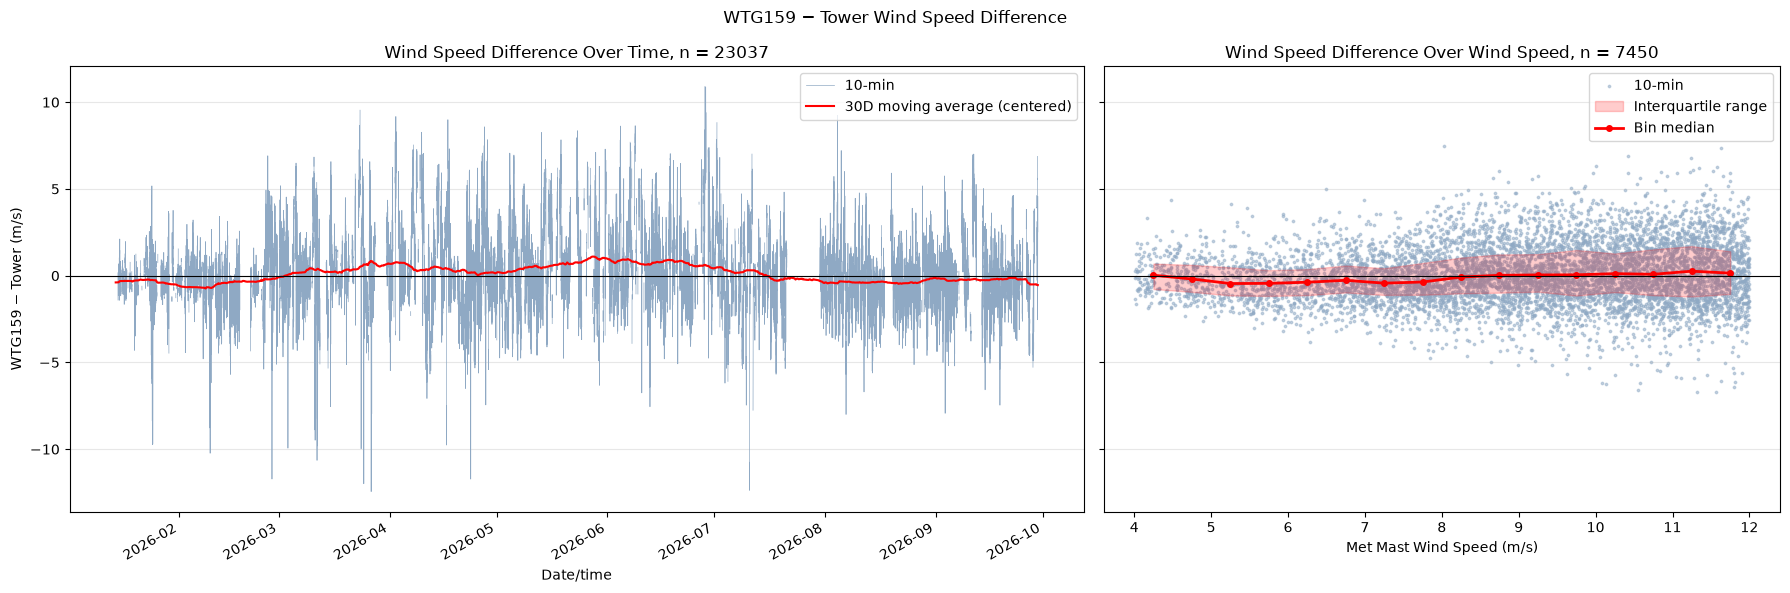

In [40]:
for t in one:
    plot_turbine_diff_metmast(data, result, t, reference = 'Tower', month = None, low = None, up = None,
                      ma = '30D', min_periods = 144, bin_width = 0.5, min_n = 30)

Turbines 150-153 give wind speed values above the metmast throughout and have increasing bias through time and with increasing wind speeds. 150 has the most dramatic. 154-159 have pretty consistent measurments through time and increasing wind speeds, mostly underestimating wind speeds. 

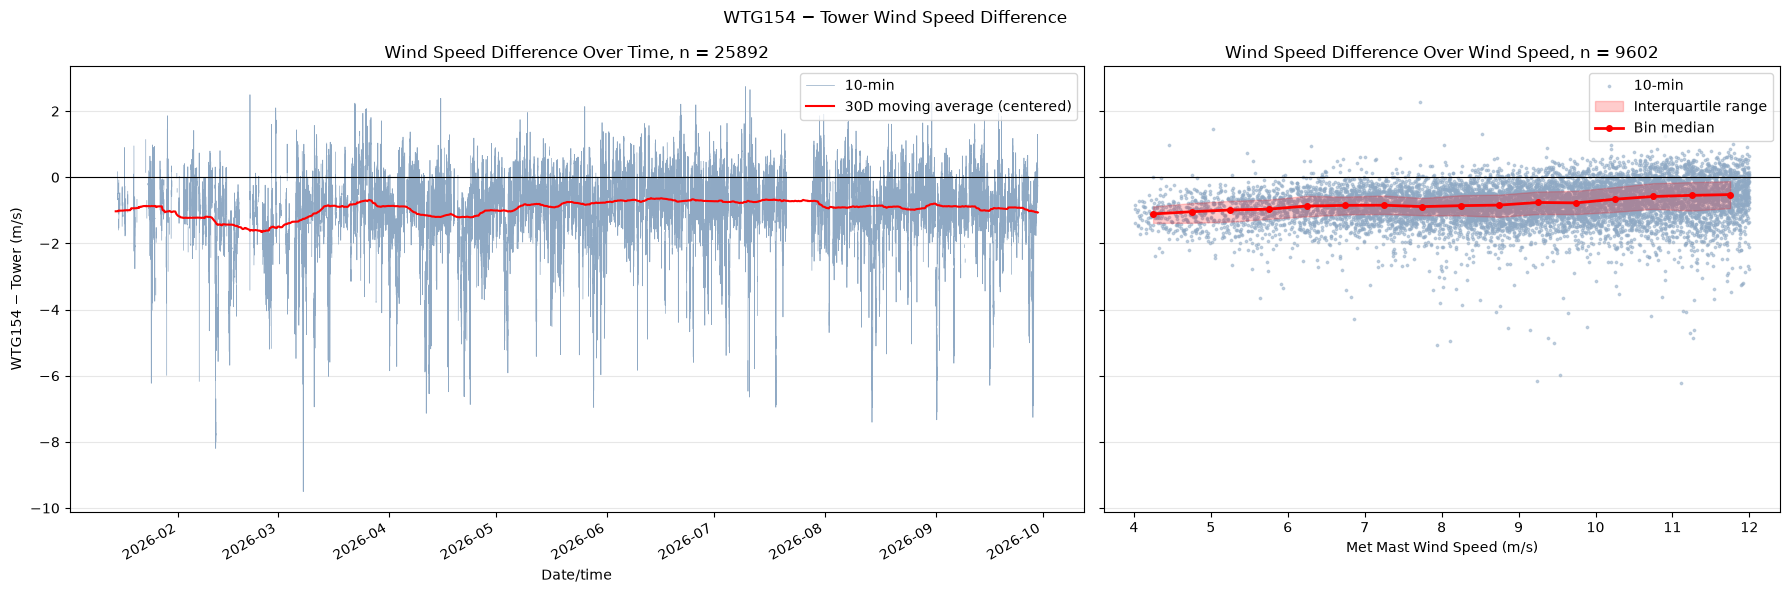

In [241]:
plot_turbine_diff_metmast(data, result, 'WTG154', reference = 'Tower', month = None, low = None, up = None,
                      ma = '30D', min_periods = 144, bin_width = 0.5, min_n = 30)